# 모듈 2 · NLP 미니프로젝트 — BERT 기반 한국어 의미 검색 시스템 개발 및 성능 비교

**기간:** 2일·총 16교시 · **체크포인트:** Day 1 `CP-01~06`, Day 2 `CP-07~10`  
**검색 모델:** TF-IDF · `klue/bert-base` · 한국어 Sentence-BERT  
**최종 결과물:** `search_docs()` + 검색 성능 보고서 + 기술적 의사결정 기록(ADR)

> 이 프로젝트는 GPT로 답변을 생성하거나 BERT를 재학습하는 프로젝트가 아닙니다. **문서의 표현 → 유사도 계산 → Top-k 검색 → 정답 평가 → 오류 분석 → 최종 검색 방식 선정**을 직접 개발합니다.
>
> **학생용 안내:** `[학생 구현]` 셀의 `TODO`를 작성하고 `raise NotImplementedError(...)`를 지운 뒤 `[공통 검증]` 셀을 실행하세요. `[기록]`으로 표시된 Markdown 셀은 실제 결과를 보고 직접 작성합니다. `생각해 볼 질문`은 별도 제출이 아닙니다.


## 00. 환경 설치와 세션 초기화 복구

GPU 세션이 초기화되더라도 첫 코드 셀부터 다시 실행할 수 있도록 구성했습니다. 패키지·모델 가중치·데이터가 없는 경우 자동으로 준비하며, 이미 저장된 파일은 재사용합니다.


**환경 설치(공통).** 필요한 Python 패키지를 한 번에 점검하고 누락되거나 호환 범위를 벗어난 패키지만 설치합니다. GPU 이미지에 이미 설치된 CUDA용 PyTorch는 가능한 한 유지하며, 설치 후 CUDA 상태를 확인합니다.


In [1]:
# [공통] 00-1 — 필요한 패키지 자동 설치
import sys, subprocess, importlib.metadata as im
from importlib.util import find_spec

# Python 패키지가 GPU 세션 초기화로 사라진 경우에도 첫 셀부터 복구합니다.
# RunPod GPU 이미지의 PyTorch/CUDA 조합은 가능하면 변경하지 않습니다.
requirements = [
    ('torch', 'torch>=2.2', '2.2'),
    ('numpy', 'numpy>=1.24', '1.24'),
    ('pandas', 'pandas>=2.0', '2.0'),
    ('matplotlib', 'matplotlib>=3.7', '3.7'),
    ('sklearn', 'scikit-learn>=1.3', '1.3'),
    ('transformers', 'transformers>=4.46,<5', '4.46'),
    ('datasets', 'datasets>=3.0,<5', '3.0'),
    ('sentence_transformers', 'sentence-transformers>=3.0,<6', '3.0'),
    ('safetensors', 'safetensors>=0.4', '0.4'),
]

# 설치 확인에는 표준 라이브러리만 사용합니다.
to_install = []
for module, spec, min_version in requirements:
    if find_spec(module) is None:
        to_install.append(spec)
    else:
        try:
            package = {'sklearn': 'scikit-learn', 'sentence_transformers': 'sentence-transformers'}.get(module, module)
            version = im.version(package)
            major_minor = tuple(int(x) for x in version.split('.')[:2])
            required = tuple(int(x) for x in min_version.split('.'))
            if major_minor < required or (module in ('transformers','datasets') and int(version.split('.')[0]) >= 5):
                to_install.append(spec)
        except (im.PackageNotFoundError, ValueError):
            to_install.append(spec)

if to_install:
    print('설치/갱신:', ', '.join(to_install))
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *to_install])
else:
    print('필수 패키지가 이미 준비되어 있습니다.')

# 이미 import한 구버전 라이브러리가 변경된 경우에는 커널 재시작 후 다시 실행하세요.
print('Python:', sys.version.split()[0])


설치/갱신: pandas>=2.0, matplotlib>=3.7, scikit-learn>=1.3, transformers>=4.46,<5, datasets>=3.0,<5, sentence-transformers>=3.0,<6, safetensors>=0.4
Python: 3.12.3


**작업 폴더와 장치 확인(공통).** `/workspace`가 있으면 프로젝트 파일을 그 아래에, 그 외 환경은 현재 작업 폴더 아래에 보관합니다. 모든 파일·폴더는 처음 실행할 때 자동으로 생성되며 추론 결과는 재실행 시 캐시를 재사용합니다.


In [2]:
# [공통] 00-2 — 프로젝트 경로·GPU·캐시 설정
import os, json, re, hashlib, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

ROOT = (Path('/workspace') if Path('/workspace').is_dir() else Path.cwd()) / 'nlp_bert_mini'
DATA_RAW = ROOT / 'data' / 'raw'
DATA_PROCESSED = ROOT / 'data' / 'processed'
WEIGHTS = ROOT / 'weights'
CACHE = ROOT / 'outputs' / 'cache'
TABLES = ROOT / 'outputs' / 'tables'
FIGURES = ROOT / 'outputs' / 'figures'
REPORTS = ROOT / 'outputs' / 'reports'
DOCS = ROOT / 'docs'
for folder in [DATA_RAW, DATA_PROCESSED, WEIGHTS, CACHE, TABLES, FIGURES, REPORTS, DOCS]:
    folder.mkdir(parents=True, exist_ok=True)

os.environ['HF_HOME'] = str(WEIGHTS / 'huggingface')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
# 로컬 저장본은 CPU로 실행합니다. 아래 기존 출력은 GPU VM에서 생성한 기록입니다.
DEVICE = torch.device('cpu')
print('실습 루트:', ROOT)
print('PyTorch:', torch.__version__, '| Device:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('GPU가 없어 CPU로 실행합니다. BERT 임베딩 계산은 더 오래 걸릴 수 있습니다.')

# [공통] CP-08의 Sentence-BERT 가중치(pytorch_model.bin)는 PyTorch 버전이 낮으면 읽지 못할 수 있어 미리 확인합니다.
try:
    _torch_major_minor = tuple(int(x) for x in torch.__version__.split('+')[0].split('.')[:2])
except ValueError:
    _torch_major_minor = None
if _torch_major_minor is not None and _torch_major_minor < (2, 6):
    print('[주의] PyTorch가 2.6 미만입니다. Day 2의 CP-08에서 Sentence-BERT 로딩이 실패할 수 있으니 강사에게 알려 주세요.')


실습 루트: /workspace/nlp_bert_mini
PyTorch: 2.8.0+cu128 | Device: cpu
GPU가 없어 CPU로 실행합니다. BERT 임베딩 계산은 더 오래 걸릴 수 있습니다.


### 세션 초기화 시 재실행 방법

1. GitHub에는 **작성한 Notebook과 최종 문서**를 저장하세요. 대용량 모델·원본 데이터는 업로드하지 않습니다.
2. 다음 날 Notebook을 내려받아 **00번 환경 셀부터 순서대로 실행**하면 폴더와 다운로드 데이터가 자동으로 준비됩니다.
3. `/workspace`가 영구 볼륨에 연결되어 있으면 캐시를 재사용합니다. 컨테이너가 삭제되는 환경에서는 다운로드와 임베딩 계산이 다시 진행될 수 있습니다.
4. CP-01~09는 Validation 질문만 사용합니다. **Test 질문의 정답은 CP-10에서 처음 열어 최종 평가**합니다.

**저장 위치:** `data/processed/` (문서·질문), `weights/` (모델 캐시), `outputs/cache/` (문서 벡터), `outputs/tables/` (성능표), `outputs/figures/` (그래프), `outputs/reports/` (결정·최종 평가).


# Day 1 — 한국어 문서 검색기 구현

**목표:** 데이터를 탐색하고 TF-IDF 검색기와 BERT 검색기를 직접 구현합니다. Day 1의 함수들은 Day 2 평가·모델 비교에서 그대로 사용합니다.

---
## CP-01. 문서·질문·정답 구조 분석 및 검색 성능 가설 수립

이번 프로젝트는 KLUE-MRC의 질문–문단 데이터를 **검색 문제**로 다시 구성합니다. 원래 KLUE-MRC는 독해/정답 구간 추출 데이터이며, 본 프로젝트는 정답 문단 하나를 연결하는 별도 검색 평가 데이터이므로 공식 KLUE-MRC 점수와 다릅니다.


**KLUE-MRC 자동 데이터 준비(공통).** 공개 데이터에서 답이 존재하는 질문과 중복되지 않는 문단을 선별해 문단 200개, Validation 질문 60개, 보류 Test 질문 20개를 만듭니다. 질문과 문단은 문서 ID로 연결되며, Test 정답은 CP-10 이전에는 열지 않습니다.


In [3]:
%pip install hf_transfer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 10.0 MB/s  0:00:00 eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [4]:
# [공통] CP-01 — 검색용 Corpus / Validation / 보류 Test 자동 준비
from datasets import load_dataset

CORPUS_FILE = DATA_PROCESSED / 'corpus_200.csv'
VALID_FILE = DATA_PROCESSED / 'questions_validation_60.csv'
TEST_FILE = DATA_PROCESSED / 'questions_test_20.csv'
META_FILE = DATA_PROCESSED / 'dataset_meta.json'

# KLUE-MRC 공식 Hugging Face 데이터셋 (validation split만 사용)
# 기존 데이터가 저장되어 있으면 다시 다운로드·선별하지 않습니다.
if not all(f.is_file() for f in (CORPUS_FILE, VALID_FILE, TEST_FILE, META_FILE)):
    raw = load_dataset('klue/klue', 'mrc', split='validation', cache_dir=str(DATA_RAW))
    eligible = []
    seen_contexts = set()
    seen_questions = set()
    for r in raw:
        if bool(r['is_impossible']):
            continue
        context, question = str(r['context']).strip(), str(r['question']).strip()
        if len(context) < 150 or not question or context in seen_contexts or question in seen_questions:
            continue
        answers = r['answers']
        answer_texts = answers.get('text', []) if isinstance(answers, dict) else []
        answer_starts = answers.get('answer_start', []) if isinstance(answers, dict) else []
        if not answer_texts:
            continue
        answer_text = str(answer_texts[0]).strip()
        if not answer_text or answer_text not in context:
            continue
        # ### 답변이 포함된 500자 이내의 문단으로 줄입니다.
        # ### (토큰 수가 MAX_LENGTH를 넘는 문단은 BERT에 넣을 때 뒷부분이 잘릴 수 있습니다.)
        answer_pos = context.find(answer_text)
        left = max(0, min(answer_pos - 180, max(0, len(context) - 500)))
        snippet = context[left:left + 500].strip()
        if answer_text not in snippet:
            continue
        eligible.append({'title': str(r.get('title', '')), 'text': snippet,
                         'question': question, 'guid': str(r['guid'])})
        seen_contexts.add(context)
        seen_questions.add(question)

    assert len(eligible) >= 200, f'선별 가능한 문단이 200개보다 적습니다: {len(eligible)}'
    rng = np.random.default_rng(SEED)
    selected = [eligible[i] for i in rng.choice(len(eligible), size=200, replace=False)]
    docs = [{'doc_id': f'D{i:03d}', 'title': r['title'], 'text': r['text']}
            for i, r in enumerate(selected)]
    corpus_out = pd.DataFrame(docs)
    candidate_idx = rng.permutation(200)[:80]
    qrows = [{'question': selected[int(idx)]['question'],
              'relevant_doc_id': f'D{int(idx):03d}'} for idx in candidate_idx]
    validation_out = pd.DataFrame([
        {'query_id': f'QV{i+1:03d}', **row} for i, row in enumerate(qrows[:60])])
    test_out = pd.DataFrame([
        {'query_id': f'QT{i+1:03d}', **row} for i, row in enumerate(qrows[60:])])

    corpus_out.to_csv(CORPUS_FILE, index=False, encoding='utf-8-sig')
    validation_out.to_csv(VALID_FILE, index=False, encoding='utf-8-sig')
    test_out.to_csv(TEST_FILE, index=False, encoding='utf-8-sig')
    META_FILE.write_text(json.dumps({
        'source': 'klue/klue · mrc · validation', 'seed': SEED,
        'num_documents': 200, 'num_validation_queries': 60, 'num_test_queries': 20,
        'sampling': 'unique contexts; one labeled relevant snippet per question',
        'notes': '수업용 단일 정답 문단 검색 세트. KLUE-MRC의 공식 검색 벤치마크가 아님.'
    }, ensure_ascii=False, indent=2), encoding='utf-8')
    print('KLUE-MRC 데이터로 검색용 소규모 데이터셋을 새로 생성했습니다.')
else:
    print('저장된 프로젝트 데이터셋을 재사용합니다.')

corpus_df = pd.read_csv(CORPUS_FILE, dtype={'doc_id': str}).fillna('')
valid_df = pd.read_csv(VALID_FILE, dtype={'query_id': str, 'relevant_doc_id': str}).fillna('')
assert len(corpus_df) == 200 and len(valid_df) == 60
assert valid_df['relevant_doc_id'].isin(corpus_df['doc_id']).all()
assert corpus_df['doc_id'].is_unique
print('문서:', len(corpus_df), '| Validation 질문:', len(valid_df), '| 별도 보류 Test: 20문항')
display(corpus_df[['doc_id', 'title', 'text']].head(3))
display(valid_df.head(3))


README.md: 0.00B [00:00, ?B/s]

mrc/train-00000-of-00001.parquet:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

mrc/validation-00000-of-00001.parquet:   0%|          | 0.00/8.68M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/17554 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5841 [00:00<?, ? examples/s]

KLUE-MRC 데이터로 검색용 소규모 데이터셋을 새로 생성했습니다.
문서: 200 | Validation 질문: 60 | 별도 보류 Test: 20문항


,doc_id,title,text
0,D000,관 (쓰개),13세기 초 인도 남부에서 채굴된 코이누르 다이아몬드는 무굴제국 등 여러 왕가의 소...
1,D001,도망자 (1995년 영화),"캄보디아 내전 시기. CIA 소속 첩보원인 아화, 아상, 그리고 뇌룡 3인은 캄보디..."
2,D002,기업들 “공공료 다 올려놓고 …”,정부 출범 초마다 어김없이 반복되는 물가 안정 대책에 업계는 바짝 긴장하고 있다. ...


,query_id,question,relevant_doc_id
0,QV001,종교 개혁 전 영국에서 인기를 끌었던 헌신은?,D015
1,QV002,세 종류의 배터리 용량을 선택할 수 있는 폭스바겐의 전기차 모델은?,D092
2,QV003,70억달러가 국비로 충당된 올림픽은?,D022


**데이터 탐색·시각화(학생 구현).** 질문과 문단의 글자 수를 계산하고 길이 분포를 그림으로 정리합니다. 관찰 결과를 바탕으로 TF-IDF와 BERT가 각각 어떤 질문에서 유리할지 예상하고 CP-09에서 다시 확인합니다.


문서 길이 통계


count    200.00000
mean     499.66000
std        0.53463
min      498.00000
25%      499.00000
50%      500.00000
75%      500.00000
max      500.00000
Name: char_length, dtype: float64


질문 길이 통계


count    60.000000
mean     29.216667
std       8.427340
min      13.000000
25%      23.750000
50%      28.000000
75%      36.000000
max      54.000000
Name: char_length, dtype: float64

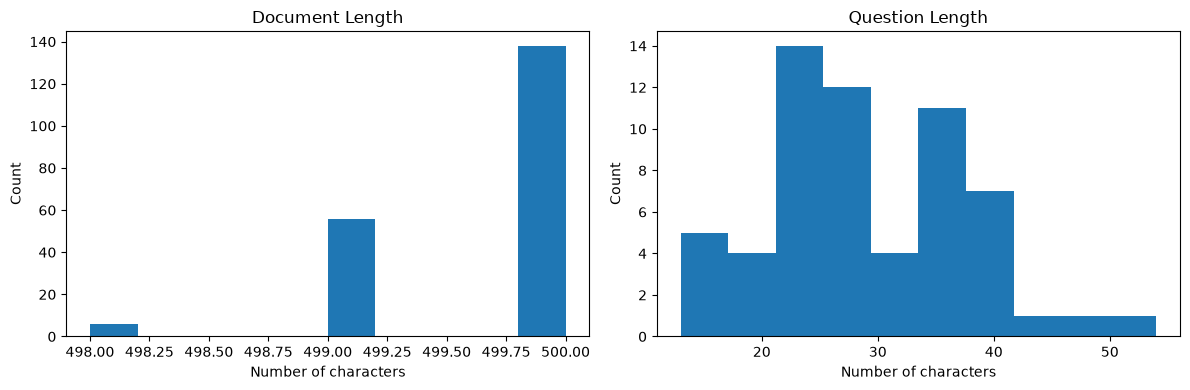

In [5]:
# [학생 구현] CP-01 — 데이터 길이 분석 및 시각화
corpus_stats = corpus_df.copy()
valid_stats = valid_df.copy()

# TODO 1-1. corpus_stats['char_length']에 문서 text의 글자 수를 계산해 넣으세요.
corpus_stats['char_length'] = corpus_stats["text"].str.len()

# TODO 1-2. valid_stats['char_length']에 질문 question의 글자 수를 계산해 넣으세요.
valid_stats["char_length"] = valid_stats["question"].str.len()

# TODO 1-3. describe()로 문서·질문 길이 통계를 출력하세요.
print("문서 길이 통계")
display(corpus_stats["char_length"].describe())
print()

print("질문 길이 통계")
display(valid_stats["char_length"].describe())
#raise NotImplementedError('CP-01 길이 분석·그래프 TODO를 완성하세요.')

# TODO 1-4. 두 길이 분포를 histogram으로 시각화하고 FIGURES에 저장하세요.
#             matplotlib의 plt.subplots(), ax.hist(), fig.savefig()를 사용합니다.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 왼쪽: 문서 길이 분포
axes[0].hist(corpus_stats["char_length"], bins=10)
axes[0].set_title("Document Length")
axes[0].set_xlabel("Number of characters")
axes[0].set_ylabel("Count")

# 오른쪽: 질문 길이 분포
axes[1].hist(valid_stats["char_length"], bins=10)
axes[1].set_title("Question Length")
axes[1].set_xlabel("Number of characters")
axes[1].set_ylabel("Count")

# 그래프 간격 조정 및 저장
fig.tight_layout()
fig.savefig(FIGURES / "cp01_length_distribution.png")
plt.show()

**질문–정답 문단 겹침 분석(공통).** TF-IDF는 질문과 문단에 같은 글자 묶음이 많이 나올수록 유리합니다. 질문의 글자 2개 묶음(2-gram) 가운데 정답 문단에도 나오는 비율을 질문마다 계산해 `valid_overlap`에 저장합니다. 겹침 비율이 낮은 질문은 문단과 다른 표현으로 물어본 질문입니다. 코드는 제공되며, 학생들은 표를 읽고 아래 기록을 작성합니다. 이 표는 CP-09에서 검색에 실패한 질문과 다시 비교합니다.

In [6]:
# [공통] CP-01 — 질문과 정답 문단의 글자 겹침 비율 (Validation 질문만 사용)

def char_bigrams(text):
    """어절 안에서 만든 글자 2개 묶음의 집합. 예: '검색 성능' → {'검색', '성능'}"""
    return {word[i:i + 2] for word in str(text).split() for i in range(len(word) - 1)}


def overlap_ratio(question, document):
    """질문의 글자 2-gram 중 문단에도 등장하는 비율(0~1)."""
    question_grams = char_bigrams(question)
    if not question_grams:
        return 0.0
    return len(question_grams & char_bigrams(document)) / len(question_grams)


_doc_text = corpus_df.set_index('doc_id')['text']
valid_overlap = valid_df[['query_id', 'question', 'relevant_doc_id']].copy()
valid_overlap['overlap'] = [overlap_ratio(q, _doc_text[d])
                            for q, d in zip(valid_overlap['question'], valid_overlap['relevant_doc_id'])]
print('질문–정답 문단 겹침 비율 통계:')
display(valid_overlap['overlap'].describe().to_frame('겹침 비율').round(3))
print('겹침 비율이 가장 낮은 질문 5개:')
display(valid_overlap.sort_values('overlap').head(5)[['query_id', 'question', 'overlap']].round(3))
valid_overlap.to_csv(TABLES / 'cp01_validation_overlap.csv', index=False, encoding='utf-8-sig')

질문–정답 문단 겹침 비율 통계:


,겹침 비율
count,60.000
mean,0.474
std,0.175
min,0.158
25%,0.333
50%,0.462
75%,0.601
max,0.882


겹침 비율이 가장 낮은 질문 5개:


,query_id,question,overlap
17,QV018,소위 천의 여왕으로 불리는 인물이 대륙에 발표한 방책은 무엇인가?,0.158
45,QV046,싸움에 대비한 체육을 다룬 교육의 명칭은?,0.167
51,QV052,한국전쟁은 남한이 일으켰다고 주장한 사람은?,0.200
50,QV051,누구나 쇼핑몰을 할 수 있게 된 것 같은 변화가 제조업에서도 일어날 수 있는 것은 ...,0.217
8,QV009,영국은 어느나라와의 싸움에서 승리해 코이누르 보석을 습득했나요?,0.227


**[기록] 결과 해석 — CP-01**

- 문서 길이와 질문 길이 분포에서 관찰한 특징: 문서의 평균 길이는 499.66자 질문의 평균 길이는 약 29.22자이다.
  문서는 대부분 500자에 가까운 반면 질문은 13~54자로 문서의 길이보다 짧다.
  따라서 검색기는 짧은 질문을 바탕으로 긴 문단에서 관련 내용을 찾아야 한다.
  
- 질문–정답 문단 겹침 비율 분포에서 관찰한 특징: 평균은 0.474, 중앙값은 0.462였다. 최솟값은 0.158, 최댓값은 0.882로 질문마다 차이가 있었다.
- 가설 1 — TF-IDF가 잘 찾을 것으로 예상하는 질문과 이유: 질문과 정답 문단에 같은 글자 묶음이 많으면 잘 찾을 것 같다
- 가설 2 — BERT 기반 검색에서 유리하거나 불리할 것 같은 질문과 이유: 표현이 달라도 의미가 비슷하면 잘 찾을 것으로 예상한다. 다만 비슷한 문단이 많거나 중요한 내용이 잘리면 찾기 어려울 수 있다.

**[CP-01 완료 기준]** 문서·질문 길이 통계와 그래프를 만들고 겹침 비율 표를 확인한 뒤, 두 검색 방식의 예상 강점·한계를 기록합니다. **Test 질문은 열지 않습니다.**


### CP-01 정리. 검색 데이터 이해

검색 시스템의 목적은 사용자가 질문을 입력하면 문단 200개 중에서 관련성이 높은 문단을 찾는 것.

| 데이터 | 개수 | 역할 |
| --- | ---: | --- |
| Corpus | 문단 200개 | 검색 대상 |
| Validation | 질문 60개 | 검색 방법 비교 및 선택 |
| Test | 질문 20개 | 선택한 방법의 최종 성능 평가 |

- 질문마다 정답 문단이 하나 있고, `relevant_doc_id`로 연결함.
- 문단과 질문의 길이, 질문과 정답 문단의 문자 겹침 비율을 확인함. 문단은 평균 499.66자, 질문은 평균 29.22자였음. 문자 겹침 비율은 평균 47.4%였음.

**실험 전 가설**

- 문자 겹침이 높으면 TF-IDF가 유리할 것이다.
- 표현이 달라도 의미가 비슷하면 BERT가 유리할 것이다.

---
## CP-02. TF-IDF 기반 기준 검색기 구현

TF-IDF는 이미 배운 전통적인 텍스트 표현 방법입니다. 이번에는 한국어 띄어쓰기의 영향을 줄이기 위해 **문자 2~3-gram TF-IDF**를 기준선으로 사용하고, 질문과 문단 간 유사도로 Top-k를 찾습니다.


**TF-IDF 검색기(학생 구현).** 문서 전체의 벡터를 만든 뒤 질문을 같은 TF-IDF 기준으로 변환합니다. 코사인 유사도에 따라 점수를 정렬하고, 앞에서부터 k개의 문서를 반환합니다.


In [7]:
# [학생 구현] CP-02 — TF-IDF + 공통 Top-k 정렬 함수
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# 2-1~2-2. 문서 전체를 문자 2~3-gram TF-IDF 벡터로 변환합니다.

# TODO 2-1. analyzer='char', ngram_range=(2, 3), max_features=30000인 TfidfVectorizer를
#           tfidf_vectorizer라는 이름으로 만드세요.
tfidf_vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(2, 3),
    max_features=30000,
)

# TODO 2-2. Corpus의 text로 fit_transform()하여 tfidf_docs를 만드세요.
tfidf_docs = tfidf_vectorizer.fit_transform(corpus_df["text"])


def top_k_results(scores, frame, k=5):
    """점수가 높은 문서 k개를 반환합니다."""
    scores = np.asarray(scores, dtype=np.float64).ravel()
    assert len(scores) == len(frame)
    k = min(max(1, int(k)), len(frame))

    # 2-3~2-4. 점수 내림차순으로 문서를 골라 1위부터 순위를 붙입니다.

    # TODO 2-3. np.argsort(-scores)로 점수 내림차순 상위 k개 인덱스를 고르세요.
    top_indices = np.argsort(-scores)[:k]

    # TODO 2-4. 위 인덱스로 rank, doc_id, score, text 키를 이 순서대로 가진 딕셔너리 리스트를 반환하세요.
    #           rank는 1부터 시작합니다. 검증 셀이 키의 순서까지 확인합니다.
    results = []
    for rank, index in enumerate(top_indices, start=1):
        document = frame.iloc[index]
        results.append({
            "rank": rank,
            "doc_id": document["doc_id"],
            "score": float(scores[index]),
            "text": document["text"],
        })
    return results


def search_tfidf(query, k=5):
    # 2-5~2-7. 문서와 같은 기준으로 질문을 변환하고 유사도를 비교합니다.

    # TODO 2-5. tfidf_vectorizer.transform()으로 질문을 벡터로 만드세요.
    query_vector = tfidf_vectorizer.transform([query])

    # TODO 2-6. cosine_similarity()로 전체 문서와의 점수를 계산하세요.
    scores = cosine_similarity(query_vector, tfidf_docs).ravel()

    # TODO 2-7. top_k_results()를 호출해 검색 결과를 반환하세요.
    return top_k_results(scores, corpus_df, k)


# 2-8. Validation 질문 하나로 검색 결과 상위 3개를 확인합니다.

# TODO 2-8. Validation 질문 하나로 상위 3개 문서를 출력해 보세요.
sample_question = valid_df.iloc[0]["question"]
print("질문:", sample_question)
print("정답 문서 ID:", valid_df.iloc[0]["relevant_doc_id"])
display(pd.DataFrame(search_tfidf(sample_question, k=3)))

질문: 종교 개혁 전 영국에서 인기를 끌었던 헌신은?
정답 문서 ID: D015


,rank,doc_id,score,text
0,1,D015,0.141820,"그것이 표준이다. 다른 장면 세트와 마찬가지로, 그림, 아이보리 미니어처 조각, 재..."
1,2,D078,0.069731,산업 혁명\n 산업혁명은 단순한 생산기술의 혁신에 의해서 발생한 생산성의 비약적 증...
2,3,D175,0.065917,마이클 베이 감독의 ‘트랜스포머:사라진 시대(사진)’가 중국에서 개봉한 영화 중 최...


**TF-IDF 검색 검증(공통).** 점수가 가장 큰 문서가 첫 번째 결과로 반환되어야 합니다. 검색 함수가 `rank·doc_id·score·text`를 모두 반환해야 BERT 검색과 같은 평가기를 재사용할 수 있습니다.


In [8]:
# [공통 검증] CP-02
_demo_corpus = pd.DataFrame({'doc_id': ['A', 'B', 'C'], 'text': ['가', '나', '다']})
_demo_rank = top_k_results([0.2, 0.9, 0.4], _demo_corpus, 2)
assert [h['doc_id'] for h in _demo_rank] == ['B', 'C']
assert list(_demo_rank[0]) == ['rank', 'doc_id', 'score', 'text']
assert tfidf_docs.shape[0] == len(corpus_df)
_check = search_tfidf(valid_df.iloc[0]['question'], 5)
assert len(_check) == 5 and len(set(h['doc_id'] for h in _check)) == 5
print('CP-02 통과: TF-IDF 검색과 Top-k 정렬 완료')


CP-02 통과: TF-IDF 검색과 Top-k 정렬 완료


**[CP-02 완료 기준]** TF-IDF 문서 행렬을 만들고 `search_tfidf(query, k)`가 유사도 내림차순의 결과를 반환하며 검증 셀을 통과합니다.


### CP-02 정리. TF-IDF 검색기 만들기

**문자 묶음 추출**

문단을 연속된 N개의 문자 단위로 나눔. 예를 들어 `세종대왕`의 2-gram은 `세종`, `종대`, `대왕`이고, 3-gram은 `세종대`, `종대왕`이다. 이번 프로젝트에서는 문단 200개에서 2-gram과 3-gram을 추출하고, 사용할 묶음은 최대 30,000개로 제한함.

**TF-IDF의 원리**

문단에 자주 나온다고 무조건 중요한 표현일까? 예를 들어 200개 중 `역사`가 180개, `조선`이 80개, `세종`이 10개, `훈민정`이 3개 문단에 나온다면 `훈민정`이 특정 문단을 구별하는 데 더 유리함.

- TF는 해당 문단에 문자 묶음이 얼마나 자주 나오는지 나타냄.
- IDF는 전체 문단에서 그 묶음이 얼마나 드문지 나타냄.
- TF × IDF를 사용해 해당 문단에 자주 나오고 다른 문단에는 드물게 나오는 묶음에 높은 중요도를 줌.

**벡터로 바꾸고 검색하기**

문자 묶음별 TF-IDF 값을 나열해 문단을 벡터로 표현함. 예를 들어 문단 1이 `[1, 2, 4, 5]`, 문단 2가 `[2, 4, 0, 0]`, 질문이 `[0, 0, 3, 4]`라면 각 위치는 문단과 질문에서 같은 묶음을 뜻함. 묶음이 30,000개라면 벡터도 30,000차원이고, 등장하지 않는 묶음은 0으로 표시함.

질문 벡터와 문단 벡터 200개의 코사인 유사도를 각각 계산해 점수 200개를 얻음. 점수가 높은 순서대로 정렬하고 상위 K개를 반환함.

**QV001 검색 결과**

정답 문단은 `D015`이다.

| 순위 | 문단 | 유사도 |
| ---: | --- | ---: |
| 1 | D015 | 0.1418 |
| 2 | D078 | 0.0697 |
| 3 | D175 | 0.0659 |

유사도는 문단의 순위를 정하는 점수다. 0.1418을 정답 확률 14.18%로 해석할 수는 없다.

**TF-IDF의 한계**

질문이 '자동차 수리 방법'이고 문단에 '차량 정비 방법'이라고 쓰여 있으면 의미는 비슷해도 겹치는 문자 묶음이 줄어듦. 표현이 다른 경우도 비교하기 위해 다음 단계에서 문맥을 반영하는 BERT 벡터를 사용함.

---
## CP-03. BERT Encoder 출력과 입력 Shape 분석

기존 KLUE-YNAT 뉴스 분류에서는 BERT 출력으로 분류했습니다. 이번에는 Classification Head가 아닌 **BERT Encoder의 토큰별 문맥 벡터(`last_hidden_state`)**를 문서 표현에 사용합니다.


**BERT 모델 로딩(공통).** `klue/bert-base`를 불러와 추론 모드로 전환합니다. 다운로드된 가중치는 `weights/`에 저장되므로 GPU 세션이 유지되는 동안 반복 다운로드하지 않습니다.


In [9]:
# [공통] CP-03 — BERT Encoder·Tokenizer 준비
from transformers import AutoTokenizer, AutoModel

BASE_MODEL = 'klue/bert-base'
MAX_LENGTH = 256
BATCH_SIZE = 16

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL, cache_dir=str(WEIGHTS))
bert_model = AutoModel.from_pretrained(BASE_MODEL, cache_dir=str(WEIGHTS), use_safetensors=True)
bert_model = bert_model.to(DEVICE).eval()
print('BERT Encoder:', BASE_MODEL, '| hidden_size:', bert_model.config.hidden_size)


tokenizer_config.json:   0%|          | 0.00/289 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/425 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/445M [00:00<?, ?B/s]

BERT Encoder: klue/bert-base | hidden_size: 768


**BERT 입력·출력 구조 확인(학생 구현).** 서로 다른 길이의 질문 두 개를 Batch로 묶고 `attention_mask`와 `last_hidden_state`의 Shape를 확인합니다. 토큰마다 벡터가 하나씩 있으므로 아직 문장 하나당 벡터 하나인 상태가 아님을 확인하세요.


In [10]:
# [학생 구현] CP-03 — 토큰 단위 문맥 벡터 확인
sample_questions = valid_df["question"].head(2).astype(str).tolist()

# TODO 3-1. tokenizer()로 질문 두 개를 padding/truncation하여 return_tensors='pt'로 만들고
#           inputs라는 이름으로 저장하세요.
inputs = tokenizer(
    sample_questions, padding=True, truncation=True,
    max_length=MAX_LENGTH, return_tensors="pt"
)

# TODO 3-2. 입력 Tensor를 DEVICE로 옮기세요.
inputs = inputs.to(DEVICE)

# TODO 3-3. torch.inference_mode() 안에서 bert_model(**inputs)를 실행하세요.
with torch.inference_mode():
    outputs = bert_model(**inputs)

# [주의] 다음 CP-04 셀이 last_hidden과 mask라는 이름을 그대로 사용합니다.
# TODO 3-4. 출력의 last_hidden_state는 last_hidden, 입력의 attention_mask는 mask라는 이름으로 저장하고
#           두 Tensor의 Shape와 문장별 유효 토큰 수를 출력하세요.
last_hidden = outputs.last_hidden_state
mask = inputs["attention_mask"]
print("BERT 출력:", tuple(last_hidden.shape))
print("Attention Mask:", tuple(mask.shape))
print("문장별 유효 토큰 수:", mask.sum(dim=1).tolist())
assert last_hidden.shape[:2] == mask.shape
assert last_hidden.shape[0] == 2


BERT 출력: (2, 19, 768)
Attention Mask: (2, 19)
문장별 유효 토큰 수: [15, 19]


**[기록] 결과 해석 CP-03**

- BERT 출력은 (2, 19, 768)이다. Batch는 질문 2개, Token은 패딩을 포함한 토큰 19개, Hidden은 토큰 하나를 표현하는 숫자 768개를 뜻한다.
- Attention Mask는 (2, 19)이며 유효 토큰 수는 각각 15개, 19개다. Mask가 0인 패딩은 길이를 맞추려고 넣은 자리이므로 평균에서 제외한다.

**[CP-03 완료 기준]** BERT Encoder 출력 Shape와 Attention Mask를 확인하고 토큰 표현과 문장 표현의 차이를 기록한다.

### CP-03 정리. BERT의 입력과 출력 이해

**토큰화와 숫자 ID**

TF-IDF는 문자 묶음에 중요도를 매기고, BERT는 주변 문맥을 반영해 토큰 벡터를 만듦. 예를 들어 '세종대왕은 한글을 만들었다.'를 토큰 단위로 나눈 뒤, 각 토큰을 모델의 어휘 사전에 있는 숫자 ID로 바꿈. `[CLS]`와 `[SEP]` 같은 특수 토큰도 포함됨. 예를 들어 `[CLS] / 세종대왕 / ##은 / 한글 / ##을 / 만들었다 / . / [SEP]`처럼 나눌 수 있고, 실제 분리와 ID는 토크나이저의 어휘 사전에 따름. ID는 토큰을 찾는 번호이고, BERT는 이 번호로 해당 토큰의 임베딩을 가져옴.

**Batch, Padding, Attention Mask**

- Batch는 여러 질문을 묶어 한 번에 처리하는 방식이다.
- 첫 번째 질문은 유효 토큰 15개, 두 번째는 19개였음. 같은 Batch에서 처리하려고 첫 번째 질문에 Padding 4개를 추가함.
- Attention Mask는 유효 토큰을 1, Padding을 0으로 표시함. BERT의 Self-Attention에서 Padding 위치를 참조하지 않게 하고, CP-04의 평균 계산에서도 같은 Mask를 사용함.

**BERT 출력**

입력 임베딩이 BERT Encoder를 지나면서 Self-Attention으로 토큰 사이의 관계를 반영하고, FFN으로 각 토큰의 표현을 추가로 변환함. 예를 들어 '나는 / 커피를 / 마신다'를 세 토큰이라고 가정하면, 각 토큰에 문맥을 반영한 768차원 벡터가 생김.

실제 출력은 `(2, 19, 768)`이다. 질문 2개, 질문마다 Padding을 포함한 토큰 자리 19개, 토큰당 768차원이라는 뜻이다. Padding 자리에도 출력 벡터가 생길 수 있음.

질문과 문단의 유사도를 비교하려면 질문 전체를 벡터 하나로 표현해야 함. CP-04에서 유효 토큰 벡터를 평균 내면 `(2, 768)`이 됨.

---
## CP-04. Attention Mask 기반 Mean Pooling 구현

BERT는 토큰마다 벡터 하나를 출력하지만 검색에서는 **질문 1개·문단 1개를 각각 하나의 벡터**로 표현해야 합니다. 패딩 위치를 제외하고 유효 토큰 벡터만 평균내는 함수를 구현합니다.


**Masked Mean Pooling(학생 구현).** Attention Mask를 `(B, T, 1)`로 바꾸어 토큰별 벡터에 곱합니다. 유효 토큰 벡터의 합을 유효 토큰 수로 나누되, 0으로 나누는 경우는 방지합니다.


In [11]:
# [학생 구현] CP-04 — Masked Mean Pooling
def mean_pooling(last_hidden_state, attention_mask):
    """패딩을 제외한 토큰 벡터 평균 (B,T,H) -> (B,H)."""

    # TODO 4-1. 패딩 위치의 벡터가 평균에 들어가지 않도록, attention_mask를 토큰 벡터와 곱할 수 있는
    #           모양 (B,T,1)로 바꾸세요.
    expanded_mask = attention_mask.unsqueeze(-1).to(last_hidden_state.dtype)

    # TODO 4-2. 토큰 벡터에 mask를 적용해 패딩 위치의 벡터를 0으로 만드세요.
    masked_vectors = last_hidden_state * expanded_mask

    # TODO 4-3. 토큰 축(T)을 따라 벡터를 합해 문장마다 벡터 하나 (B,H)가 되게 하세요.
    vector_sums = masked_vectors.sum(dim=1)

    # TODO 4-4. 문장별 유효 토큰 수로 나누어 평균 (B,H)를 반환하세요.
    #           유효 토큰 수가 0인 경우에도 0으로 나누지 않도록 처리합니다.
    token_counts = expanded_mask.sum(dim=1).clamp(min=1)
    return vector_sums / token_counts

sentence_vecs = mean_pooling(last_hidden, mask)
print("Pooling 후:", tuple(sentence_vecs.shape))

Pooling 후: (2, 768)


**Pooling 숫자 검증(공통).** 마지막 토큰에 매우 큰 숫자가 들어 있어도 `attention_mask=0`이면 평균에 포함되면 안 됩니다. 아래 검증 셀은 실제 BERT 가중치 없이 작은 Tensor만으로 정답을 확인합니다.


In [12]:
# [공통 검증] CP-04 — Padding을 제외한 평균
_toy_hidden = torch.tensor([[[1., 0.], [3., 2.], [100., 100.]],
                            [[2., 4.], [20., 20.], [40., 40.]]])
_toy_mask = torch.tensor([[1, 1, 0], [1, 0, 0]])
_toy_out = mean_pooling(_toy_hidden, _toy_mask)
assert _toy_out.shape == (2, 2)
assert torch.allclose(_toy_out, torch.tensor([[2., 1.], [2., 4.]]), atol=1e-6)
assert sentence_vecs.shape == (2, bert_model.config.hidden_size)
print('CP-04 통과: Padding 제외 평균과 (Batch, Hidden) Shape 확인')


CP-04 통과: Padding 제외 평균과 (Batch, Hidden) Shape 확인


**[CP-04 완료 기준]** `mean_pooling()`을 완성하고 유효 토큰만 평균을 낸 검증을 통과합니다. **생각해 볼 질문:** `attention_mask`를 무시하면 문장 길이에 따른 패딩이 검색 결과에 어떤 영향을 줄까요?


### CP-04 정리. 토큰 벡터를 문장 벡터로 합치기

질문이 15토큰이면 `(15, 768)`, 문단이 200토큰이면 `(200, 768)`이다. 질문 전체와 문단 전체를 비교하려면 토큰 수가 달라도 각각 같은 차원의 벡터 하나로 표현해야 함.

**Mean Pooling 예시**

| 토큰 | 1번째 차원 | 2번째 | 3번째 | 4번째 |
| --- | ---: | ---: | ---: | ---: |
| 나는 | 1 | 2 | 3 | 4 |
| 커피를 | 3 | 4 | 5 | 6 |
| 마신다 | 5 | 6 | 7 | 8 |
| 합계 | 9 | 12 | 15 | 18 |

합계를 토큰 수 3으로 나누면 `[3, 4, 5, 6]`이다. `(3, 4)`가 `(4,)`로 바뀐 것. 실제 BERT 출력에서는 768개 차원 각각에 대해 평균을 계산함.

**Padding을 제외한 평균**

1. 토큰 벡터에 Attention Mask를 곱함. 유효 토큰은 그대로 두고 Padding 벡터의 값은 모두 0으로 바꿈.
2. 각 차원별로 토큰 벡터를 더함.
3. Mask에서 1의 개수, 즉 유효 토큰 수로 나눔.

Padding은 입력 길이를 맞추는 자리라 평균에 포함하면 문장 벡터 값이 달라짐. 적용 결과 `(2, 19, 768)`이 `(2, 768)`로 바뀌었고, 질문마다 768차원 벡터 하나를 얻음.

일반 BERT는 문장 유사도 검색에 특화해 학습한 모델이 아니어서, Mean Pooling만으로 검색에 적합한 벡터가 만들어지는지는 실험으로 확인해야 함.

---
## CP-05. BERT 문서 임베딩과 코사인 유사도 계산

문서 200개를 BERT Encoder와 Pooling을 통과시켜 같은 차원의 벡터로 변환합니다. 질문 벡터와 각 문서 벡터의 **코사인 유사도**를 직접 계산합니다.


**BERT 임베딩 Batch 처리(학생 구현).** 문서를 한 번에 모두 처리하면 메모리를 많이 사용하므로 16개씩 Tokenizer → BERT → Mean Pooling을 반복합니다. 결과는 NumPy 배열로 합치며, 이후 GPU를 다시 사용하지 않도록 저장합니다.


In [13]:
# [학생 구현] CP-05 — BERT 임베딩 생성 함수
def encode_bert_texts(texts, batch_size=BATCH_SIZE):
    """문장/문단 리스트 -> (N, Hidden) NumPy 배열."""
    texts = [str(t) for t in texts]
    vectors = []
    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]

        # TODO 5-1. batch를 tokenizer()로 Tensor로 변환하고 DEVICE로 옮기세요.
        encoded = tokenizer(
            batch, padding=True, truncation=True,
            max_length=MAX_LENGTH, return_tensors="pt"
        ).to(DEVICE)

        # TODO 5-2. 추론 모드에서 bert_model(**encoded)로 last_hidden_state를 얻으세요.
        with torch.inference_mode():
            hidden = bert_model(**encoded).last_hidden_state

            # TODO 5-3. mean_pooling()을 적용하고 CPU NumPy 배열로 vectors에 추가하세요.
            pooled = mean_pooling(hidden, encoded["attention_mask"])
        vectors.append(pooled.cpu().numpy())
    return np.vstack(vectors) if vectors else np.empty((0, bert_model.config.hidden_size))


def cosine_scores(query_vector, document_matrix):
    """질문 벡터 (H,)와 문서 행렬 (N,H) -> 유사도 (N,)."""
    query_vector = np.asarray(query_vector, dtype=np.float64).reshape(-1)
    document_matrix = np.asarray(document_matrix, dtype=np.float64)

    # TODO 5-4. 질문 벡터와 각 문서 벡터의 내적을 구하세요. 결과는 문서 수만큼의 값 (N,)입니다.
    dot_products = document_matrix @ query_vector

    # TODO 5-5. 질문 벡터의 크기(노름)와 각 문서 벡터의 크기를 구하세요.
    query_norm = np.linalg.norm(query_vector)
    document_norms = np.linalg.norm(document_matrix, axis=1)

    # TODO 5-6. 내적을 두 크기의 곱으로 나눈 코사인 유사도 배열 (N,)을 반환하세요.
    #           분모가 0이 되는 경우에도 오류가 나지 않도록 처리합니다.
    denominators = query_norm * document_norms
    return np.divide(
        dot_products, denominators,
        out=np.zeros_like(dot_products), where=denominators > 0
    )

**문서 임베딩 캐싱(공통).** `bert_corpus_200_256.npy`가 이미 있으면 다시 계산하지 않습니다. 다만 저장된 벡터가 **지금의 `encode_bert_texts()`가 계산한 결과와 같은지** 앞 문서 4개로 먼저 확인합니다. 함수를 고친 뒤라서 결과가 다르면 전체를 다시 계산해 덮어쓰므로, 예전에 잘못 계산된 벡터가 계속 쓰이지 않습니다.

In [14]:
# [공통] CP-05 — BERT Corpus 임베딩 생성/재사용
BERT_DOC_CACHE = CACHE / 'bert_corpus_200_256.npy'


def load_or_encode(cache_file, texts, n_check=4):
    """저장된 임베딩이 현재 encode_bert_texts()의 결과와 같을 때만 재사용합니다.

    앞 n_check개를 다시 계산해 저장본과 비교하고, 다르면(함수를 고친 경우 등) 전체를 다시 계산해 덮어씁니다.
    """
    texts = [str(t) for t in texts]
    expected_shape = (len(texts), bert_model.config.hidden_size)
    if cache_file.is_file():
        cached = np.load(cache_file)
        if cached.shape == expected_shape:
            fresh = encode_bert_texts(texts[:n_check])
            if fresh.shape == cached[:n_check].shape and np.allclose(fresh, cached[:n_check], atol=1e-3):
                print('저장된 임베딩 재사용:', cache_file.name)
                return cached
        print('저장된 임베딩이 현재 함수의 결과와 달라 다시 계산합니다:', cache_file.name)
    vectors = encode_bert_texts(texts)
    np.save(cache_file, vectors)
    return vectors


bert_doc_vectors = load_or_encode(BERT_DOC_CACHE, corpus_df['text'].tolist())
print('BERT 문서 벡터 Shape:', bert_doc_vectors.shape)

BERT 문서 벡터 Shape: (200, 768)


**코사인 유사도 검증(공통).** 질문과 같은 방향의 문서 벡터는 유사도가 1에 가까워야 합니다. 문서가 200개이므로 질문 하나에 대한 점수 배열도 반드시 길이 200이어야 합니다.


In [15]:
# [공통 검증] CP-05
_test_scores = cosine_scores(np.array([1., 0.]),
                             np.array([[1., 0.], [0., 1.], [-1., 0.]]))
assert np.allclose(_test_scores, [1., 0., -1.], atol=1e-6)
assert bert_doc_vectors.shape == (200, bert_model.config.hidden_size)
assert np.isfinite(bert_doc_vectors).all()
print('CP-05 통과: 코사인 유사도 및 BERT 문서 임베딩 정상')


CP-05 통과: 코사인 유사도 및 BERT 문서 임베딩 정상


**[CP-05 완료 기준]** BERT 임베딩 (200, 768) 배열을 저장하고, 직접 작성한 `cosine_scores()`가 숫자 검증을 통과합니다.


### CP-05 정리. 문단 200개를 벡터로 만들기

CP-04의 방법을 검색 대상 문단 200개에 적용함. 문단 벡터를 미리 저장해 두면, 검색할 때 질문 벡터만 만들어 문단 벡터와 비교할 수 있음.

**Batch로 나눠 문단 벡터 만들기**

- Batch Size는 16이다. 16개씩 12번 처리하고 마지막 8개를 처리해 총 13개 Batch가 됨. 한 번에 처리하는 문단 수를 줄이면 GPU 메모리 사용량도 줄일 수 있음.
- 입력이 256토큰을 넘으면 잘라내고, 같은 Batch의 더 짧은 입력에는 Padding을 추가함.
- 문단 16개가 모두 256개의 토큰 자리를 갖는 Batch라면 BERT 출력은 `(16, 256, 768)`이다. Padding을 제외하고 평균을 내면 `(16, 768)`이 됨.
- 각 Batch의 출력을 합치면 `(200, 768)`이다. 이번 프로젝트에서는 벡터를 파일에 저장해 재사용함. RAG에서도 문단 벡터를 미리 만들어 검색에 활용할 수 있고, 규모가 크면 벡터 DB를 쓰기도 함.

**코사인 유사도**

두 벡터의 방향이 얼마나 비슷한지 보는 방법이다.

| 두 벡터의 각도 | 유사도 | 관계 |
| ---: | ---: | --- |
| 0° | 1 | 같은 방향 |
| 90° | 0 | 직각 |
| 180° | -1 | 반대 방향 |

질문 하나를 768차원 벡터로 바꾸고, 저장한 문단 벡터 200개와 각각 비교하면 점수 배열 `(200,)`을 얻음. 점수가 높을수록 벡터 공간에서 방향이 비슷하고, 실제 의미를 얼마나 잘 반영하는지는 임베딩 모델에 따라 달라짐.

---
## CP-06. Top-k BERT 문서 검색기 완성

이제 질문을 같은 BERT Encoder로 벡터화하고 저장된 문서 벡터들과 비교합니다. CP-02에서 구현한 `top_k_results()`를 재사용해 **검색기가 하나의 완성된 프로그램**으로 동작하도록 연결합니다.


**BERT 검색 함수(학생 구현).** 질문 하나를 BERT 임베딩으로 변환해 문서 200개와 코사인 유사도를 계산합니다. 상위 k개 결과의 문서 ID, 유사도, 원문을 같은 인터페이스로 반환해야 Day 2에서 두 검색기를 공정하게 평가할 수 있습니다.


In [16]:
# [학생 구현] CP-06 — BERT 검색 함수
bert_query_cache = {}  # Day 2에 일괄 준비할 검색 질문 벡터 캐시

def search_bert(query, k=5):
    query = str(query)

    # TODO 6-1. 캐시에 query가 있다면 재사용하고, 없다면 encode_bert_texts([query])[0]를 사용하세요.
    if query not in bert_query_cache:
        bert_query_cache[query] = encode_bert_texts([query])[0]
    query_vector = bert_query_cache[query]

    # TODO 6-2. cosine_scores()로 corpus 전체 문서와의 점수를 구하세요.
    scores = cosine_scores(query_vector, bert_doc_vectors)

    # TODO 6-3. top_k_results()를 호출하여 상위 k개의 검색 결과를 반환하세요.
    return top_k_results(scores, corpus_df, k)

# TODO 6-4. Validation 질문 하나를 골라 BERT 검색 결과 Top-3를 표로 확인하세요.
sample_question = valid_df.iloc[0]["question"]
print("질문:", sample_question)
print("정답 문서 ID:", valid_df.iloc[0]["relevant_doc_id"])
display(pd.DataFrame(search_bert(sample_question, k=3)))

질문: 종교 개혁 전 영국에서 인기를 끌었던 헌신은?
정답 문서 ID: D015


,rank,doc_id,score,text
0,1,D015,0.693191,"그것이 표준이다. 다른 장면 세트와 마찬가지로, 그림, 아이보리 미니어처 조각, 재..."
1,2,D124,0.645155,아)로 떨어졌다. 많은 매체가 관련 기사를 내보냈는데 어느 정도 이런 추락을 예상했...
2,3,D068,0.640854,서양 근세의 교육은 14세기에서 17세기 초반 까지의 유럽 세계의 교육활동을 의미한...


**검색기 출력 검증(공통).** 두 검색 방식이 반환하는 항목과 순위 형식이 동일한지 확인합니다. 단위 테스트는 검색 결과의 구조만 확인하며, 이 단계에서 검색 점수가 높아야 한다는 조건을 요구하지 않습니다.


In [17]:
# [공통 검증] CP-06
_question = valid_df.iloc[0]['question']
for _search_fn in [search_tfidf, search_bert]:
    _hits = _search_fn(_question, 3)
    assert len(_hits) == 3 and [h['rank'] for h in _hits] == [1, 2, 3]
    assert all({'doc_id', 'text', 'score'} <= set(h) for h in _hits)
    assert _hits[0]['score'] >= _hits[1]['score'] >= _hits[2]['score']
print('CP-06 통과: TF-IDF / BERT Top-k 검색기 완성')


CP-06 통과: TF-IDF / BERT Top-k 검색기 완성


**[Day 1 완료 기준]** 문서 분석과 검색 성능 가설, TF-IDF 검색기, BERT Masked Mean Pooling, 코사인 유사도, `search_bert()`와 검증 셀을 모두 완료합니다. **Day 1 종료 후 작성한 Notebook을 GitHub에 저장하세요.**


### CP-06 정리. BERT 검색기 완성

CP-03의 토큰 벡터, CP-04의 Masked Mean Pooling, CP-05의 문단 임베딩과 코사인 유사도 함수를 검색기로 연결함.

**질문 벡터 캐시**

- Cache Hit이면 기존 질문 벡터를 불러와 BERT 연산을 생략함.
- Cache Miss이면 질문을 토큰화하고, BERT와 Masked Mean Pooling으로 질문 벡터를 만든 뒤 캐시에 저장함.
- 어느 쪽이든 질문 벡터를 저장된 문단 벡터 200개와 비교함. 점수 200개를 내림차순으로 정렬해 Top-K 문단을 반환함.

CP-05의 캐시는 문단 벡터를 파일에 저장하고, CP-06의 캐시는 같은 질문의 벡터를 실행 중에 재사용함. 둘 다 반복되는 BERT 연산을 줄이기 위한 것.

**같은 질문으로 검색해 본 결과**

첫 번째 Validation 질문 `QV001`을 두 검색기에 입력함. 정답 문단은 `D015`이다.

| 순위 | TF-IDF | BERT |
| ---: | --- | --- |
| 1 | D015 / 0.1418 | D015 / 0.6932 |
| 2 | D078 / 0.0697 | D124 / 0.6452 |
| 3 | D175 / 0.0659 | D068 / 0.6409 |

둘 다 정답을 1위에서 찾았고, 2위와 3위는 달랐음. TF-IDF는 문자 묶음의 중요도를, BERT는 문맥을 반영한 벡터를 사용해 비교함. 점수 분포가 다르므로 두 검색기의 유사도 숫자만으로 성능을 비교하기는 어려움. Validation 질문 60개 전체에서 각 검색기가 정답을 몇 위에 찾았는지 평가해야 함.

TF-IDF와 같은 반환 형식, 요청한 K개 문단, 검색 순위, 유사도 내림차순을 확인했고 CP-06 공통 검증을 통과함.

Day 1에서는 데이터를 살펴보고 두 검색기를 구현함. Day 2에서는 Sentence-BERT를 추가해 Validation에서 세 방법을 비교하고, 선택한 방법을 Test로 최종 평가함.

# Day 2 — 검색 성능 평가·오류 분석·최종 검색 방식 선정

둘째 날은 `CP-07~10`을 진행합니다. **Validation 질문에서만 모델을 비교하고 선택**한 후, 보류 Test 질문은 CP-10의 최종 평가에 사용합니다.

---
## CP-07. 검색 평가 함수 구현 — Hit@1 · Recall@3 · MRR@5

분류에서 Accuracy·F1을 계산했던 것처럼 문서 검색에도 평가 기준이 필요합니다. 이번에는 질문마다 **정답 문서가 하나**이므로, 그 문서가 몇 위에 검색되었는지로 성능을 평가합니다.


**검색 평가 지표 구현(학생 구현).** Hit@1은 정답 문서가 첫 번째인지, Recall@3은 상위 3개에 있는지, MRR@5는 상위 5개 안에서의 정답 순위 역수입니다. 질문별 지표를 평균하여 전체 검색 성능을 계산합니다.


In [18]:
# [학생 구현] CP-07 — 검색 평가 지표

def retrieval_metrics(hits, relevant_doc_id):
    """하나의 정답 문서 기준 Hit@1·Recall@3·MRR@5·rank 반환."""
    doc_ids = [h['doc_id'] for h in hits]

    # TODO 7-1. relevant_doc_id가 doc_ids에 있으면 순위(1부터 시작)를 구하세요. 없으면 None.
    rank = doc_ids.index(relevant_doc_id) + 1 if relevant_doc_id in doc_ids else None

    # TODO 7-2. Hit@1, Recall@3, MRR@5를 각각 계산해
    #             {'hit1': ..., 'recall3': ..., 'mrr5': ..., 'rank': ...} 형태의 딕셔너리로 반환하세요.
    #             rank에는 7-1에서 구한 순위(없으면 None)를 넣습니다. CP-09에서 이 키 이름을 그대로 사용합니다.
    #             정답이 상위 5개에 없으면 MRR@5는 0입니다.
    hit1 = int(rank == 1)
    recall3 = int(rank is not None and rank <= 3)
    mrr5 = 1 / rank if rank is not None and rank <= 5 else 0.0

    return {
        'hit1': hit1,
        'recall3': recall3,
        'mrr5': mrr5,
        'rank': rank
    }


def evaluate_search(search_fn, questions_df):
    """질문 데이터 전체 검색 결과: (summary_dict, detail_DataFrame)."""
    rows = []

    for row in questions_df.itertuples(index=False):

        # TODO 7-3. search_fn(row.question, 5)를 호출하세요.
        hits = search_fn(row.question, 5)

        # TODO 7-4. retrieval_metrics()로 정답 문서 순위·지표를 계산하세요.
        metrics = retrieval_metrics(hits, row.relevant_doc_id)

        # TODO 7-5. query_id, question, relevant_doc_id, hit1, recall3, mrr5, rank, top1_doc_id를
        #           키로 가진 딕셔너리를 rows에 추가하세요.
        rows.append({
            'query_id': row.query_id,
            'question': row.question,
            'relevant_doc_id': row.relevant_doc_id,
            'hit1': metrics['hit1'],
            'recall3': metrics['recall3'],
            'mrr5': metrics['mrr5'],
            'rank': metrics['rank'],
            'top1_doc_id': hits[0]['doc_id'] if hits else None
        })

    detail = pd.DataFrame(rows)

    # TODO 7-6. hit1/recall3/mrr5 평균을 summary 딕셔너리로 만들고 (summary, detail)을 반환하세요.
    summary = {
        'hit1': detail['hit1'].mean(),
        'recall3': detail['recall3'].mean(),
        'mrr5': detail['mrr5'].mean()
    }

    return summary, detail

**평가 지표 검증(공통).** 정답이 2위라면 Hit@1=0, Recall@3=1, MRR@5=0.5가 되어야 합니다. 먼저 작은 예제를 통과시킨 뒤 실제 Validation 질문 전체에 적용합니다.


In [19]:
# [공통 검증] CP-07
_toy_hits = [{'doc_id': 'A'}, {'doc_id': 'B'}, {'doc_id': 'C'},
             {'doc_id': 'D'}, {'doc_id': 'E'}]
_m = retrieval_metrics(_toy_hits, 'B')
assert _m['hit1'] == 0 and _m['recall3'] == 1 and np.isclose(_m['mrr5'], 0.5)
assert retrieval_metrics(_toy_hits, 'A')['hit1'] == 1
assert retrieval_metrics(_toy_hits, 'Z')['mrr5'] == 0
print('CP-07 검색 지표 단위 테스트 통과')


CP-07 검색 지표 단위 테스트 통과


**Validation 질문 임베딩 캐시(공통).** BERT 질문을 한 번에 Batch로 임베딩하여 CP-07~09의 반복 평가에서 재사용합니다. 캐시를 준비한 뒤 TF-IDF와 BERT의 실제 Validation 성능을 계산합니다.


In [20]:
# [공통] CP-07 — 질문 벡터 일괄 계산 및 기준 성능 측정
BERT_VALID_CACHE = CACHE / 'bert_validation_60_256.npy'
# ### CP-05의 load_or_encode()로, 저장본이 현재 함수의 결과와 같을 때만 재사용합니다.
valid_bert_vecs = load_or_encode(BERT_VALID_CACHE, valid_df['question'].tolist())
bert_query_cache.update({str(q): vec for q, vec in
                         zip(valid_df['question'].tolist(), valid_bert_vecs)})

tfidf_summary, tfidf_detail = evaluate_search(search_tfidf, valid_df)
bert_summary, bert_detail = evaluate_search(search_bert, valid_df)
print('TF-IDF:', tfidf_summary)
print('BERT:', bert_summary)
assert len(tfidf_detail) == len(bert_detail) == len(valid_df)


TF-IDF: {'hit1': np.float64(0.8833333333333333), 'recall3': np.float64(0.9666666666666667), 'mrr5': np.float64(0.9166666666666666)}
BERT: {'hit1': np.float64(0.6666666666666666), 'recall3': np.float64(0.8333333333333334), 'mrr5': np.float64(0.7588888888888888)}


**[CP-07 완료 기준]** 세 가지 지표의 단위 테스트를 통과하고, TF-IDF와 BERT의 Validation Hit@1·Recall@3·MRR@5를 계산합니다.


### CP-07 정리. 검색 성능 평가

Day 1에서 TF-IDF와 BERT 검색기를 만들었다. 질문 하나에서 정답 문단을 1위로 찾았어도 다른 질문에서는 결과가 달라질 수 있다. 그래서 같은 Validation 질문 60개를 두 검색기에 넣고, 정답 문단이 몇 위에 나오는지 비교했다.

**평가 지표**

- Hit@1은 첫 번째 결과가 정답인지 본다. 예를 들어 질문 60개 중 45개에서 정답이 1위이면 45 ÷ 60 = 0.75(75%)이다.
- Recall@3은 상위 3개 결과에 정답이 들어 있는지 본다. 이번 프로젝트에서는 질문마다 정답 문단이 하나라서, 정답이 1~3위에 있으면 1이고 4위 이하거나 결과에 없으면 0이다.
- MRR@5는 상위 5개에서 정답을 얼마나 높은 순위로 찾았는지 본다. 질문별 점수인 RR@5는 `1 ÷ 정답 순위`이고, 상위 5개에 정답이 없으면 0이다. 질문별 RR@5를 평균 내면 MRR@5가 된다.

| 정답 순위 | Hit@1 | Recall@3 | RR@5 |
| --- | ---: | ---: | ---: |
| 1위 | 1 | 1 | 1 |
| 2위 | 0 | 1 | 0.5 |
| 3위 | 0 | 1 | 0.333 |
| 4위 | 0 | 0 | 0.25 |
| 5위 | 0 | 0 | 0.2 |
| 상위 5개 밖 | 0 | 0 | 0 |

Hit@1과 Recall@3은 기준 순위 안에 들었는지 확인한다. MRR@5는 같은 상위 5개 안에서도 정답 순위가 높을수록 점수를 더 준다.

**평가 함수 흐름**

1. `retrieval_metrics()`는 질문 하나의 Top-5 결과에서 정답 문단 ID를 찾고, 정답 순위와 질문별 점수를 반환한다.
2. `evaluate_search()`는 Validation 질문마다 Top-5 검색과 지표 계산을 반복한다. `summary`에는 지표별 평균을, `detail`에는 질문별 점수와 정답 순위를 담는다.
3. BERT는 Validation 질문 60개의 벡터를 `(60, 768)`로 미리 만들어 저장했다. 평가하는 동안에는 캐시에서 질문 벡터를 불러다 썼다.

**Validation 평가 결과**

| 평가 지표 | TF-IDF | BERT |
| --- | ---: | ---: |
| Hit@1 | 88.33% | 66.67% |
| Recall@3 | 96.67% | 83.33% |
| MRR@5 | 0.9167 | 0.7589 |
| 정답 1위 | 53/60 | 40/60 |
| 정답 상위 3개 | 58/60 | 50/60 |

검색 지표 단위 테스트를 통과했다. 이번 평가에서는 TF-IDF가 세 지표 모두 높았다. 다음 단계에서는 문장 간 유사도에 맞춰 학습한 Sentence-BERT를 추가해, 일반 BERT에서 평균 낸 문장 벡터와 검색 결과가 어떻게 다른지 확인한다.

---
## CP-08. TF-IDF·BERT·Sentence-BERT 검색 성능 비교

일반 BERT의 Mean Pooling은 검색 작업에 맞춰 학습된 문장 임베딩과 다를 수 있습니다. 한국어 문장 유사도 모델을 추가하고 세 검색 방식의 실제 Validation 결과를 비교합니다.


**한국어 Sentence-BERT 준비(공통).** `snunlp/KR-SBERT-V40K-klueNLI-augSTS`를 이용해 문서 벡터를 생성합니다. 이미 계산한 문서·질문 임베딩이 있으면 저장된 `.npy` 파일을 사용하며, 별도의 Fine-tuning은 하지 않습니다.


In [21]:
# [공통] CP-08 — Sentence-BERT 문서/질문 임베딩 준비
from sentence_transformers import SentenceTransformer

SBERT_MODEL = 'snunlp/KR-SBERT-V40K-klueNLI-augSTS'
sbert_model = SentenceTransformer(SBERT_MODEL, device=str(DEVICE), cache_folder=str(WEIGHTS))
# ### 기본 BERT와 비교할 때 문서가 잘리는 최대 토큰 길이를 통일합니다.
sbert_model.max_seq_length = MAX_LENGTH
SBERT_DOC_CACHE = CACHE / 'sbert_corpus_200.npy'
SBERT_VALID_CACHE = CACHE / 'sbert_validation_60.npy'

if SBERT_DOC_CACHE.is_file():
    sbert_doc_vectors = np.load(SBERT_DOC_CACHE)
else:
    sbert_doc_vectors = sbert_model.encode(corpus_df['text'].tolist(), batch_size=16,
                                            normalize_embeddings=True, convert_to_numpy=True)
    np.save(SBERT_DOC_CACHE, sbert_doc_vectors)
if SBERT_VALID_CACHE.is_file():
    sbert_valid_vectors = np.load(SBERT_VALID_CACHE)
else:
    sbert_valid_vectors = sbert_model.encode(valid_df['question'].tolist(), batch_size=16,
                                              normalize_embeddings=True, convert_to_numpy=True)
    np.save(SBERT_VALID_CACHE, sbert_valid_vectors)
assert len(sbert_doc_vectors) == len(corpus_df)
assert len(sbert_valid_vectors) == len(valid_df)
sbert_query_cache = {str(q): v for q, v in zip(valid_df['question'], sbert_valid_vectors)}
print('SBERT 문서 벡터:', sbert_doc_vectors.shape)


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/467M [00:00<?, ?B/s]

... (4 outputs left out)

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

SBERT 문서 벡터: (200, 768)


**세 가지 검색 방식 비교(학생 구현).** Sentence-BERT 검색 함수를 작성하고 앞에서 만든 `evaluate_search()`로 동일한 Validation 질문을 평가합니다. 세 방식의 지표를 하나의 DataFrame과 막대그래프로 정리하세요.


,hit1,recall3,mrr5
tfidf,0.883333,0.966667,0.916667
bert,0.666667,0.833333,0.758889
sbert,0.766667,0.883333,0.820833


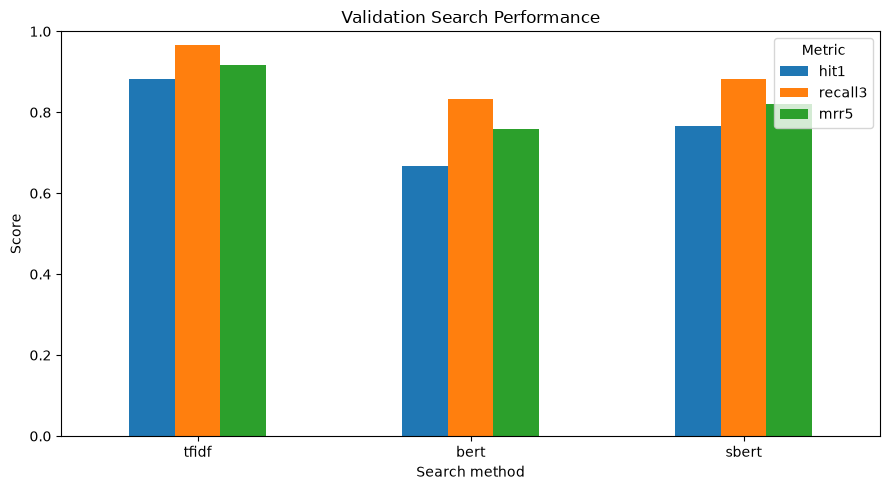

In [22]:
# [학생 구현] CP-08 — Sentence-BERT 검색 + 성능 비교

def search_sbert(query, k=5):
    query = str(query)

    # TODO 8-1. 질문 벡터가 캐시에 있으면 재사용하고, 없으면 새로 생성한다.
    if query not in sbert_query_cache:
        sbert_query_cache[query] = sbert_model.encode(
            [query],
            normalize_embeddings=True,
            convert_to_numpy=True
        )[0]

    query_vector = sbert_query_cache[query]

    # TODO 8-2. 질문과 문단의 코사인 유사도를 계산하고 상위 k개를 반환한다.
    scores = cosine_scores(query_vector, sbert_doc_vectors)
    return top_k_results(scores, corpus_df, k)


# TODO 8-3. Sentence-BERT로 Validation 질문을 평가한다.
sbert_summary, sbert_detail = evaluate_search(search_sbert, valid_df)


# TODO 8-4. 세 검색기의 평가 결과를 하나의 표로 만든다.
comparison_df = pd.DataFrame(
    [tfidf_summary, bert_summary, sbert_summary],
    index=["tfidf", "bert", "sbert"]
)[["hit1", "recall3", "mrr5"]]

display(comparison_df)


# TODO 8-5. 비교표를 CSV로 저장하고 막대그래프를 그린다.
comparison_df.to_csv(
    TABLES / "cp08_validation_comparison.csv",
    encoding="utf-8-sig"
)

ax = comparison_df.plot(
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 1),
    rot=0
)

ax.set_title("Validation Search Performance")
ax.set_xlabel("Search method")
ax.set_ylabel("Score")
ax.legend(title="Metric")

fig = ax.get_figure()
fig.tight_layout()
fig.savefig(FIGURES / "cp08_validation_comparison.png")
plt.show()

**비교 결과 검증(공통).** 세 검색기의 검색 결과 형식이 같고 지표가 0~1 사이인지 확인합니다. 성능의 순위는 데이터에 따라 달라지므로 BERT나 Sentence-BERT가 무조건 높아야 한다는 조건은 없습니다.


In [23]:
# [공통 검증] CP-08
assert comparison_df.index.tolist() == ['tfidf', 'bert', 'sbert']
assert (comparison_df[['hit1', 'recall3', 'mrr5']] >= 0).all().all()
assert (comparison_df[['hit1', 'recall3', 'mrr5']] <= 1).all().all()
assert len(sbert_detail) == len(valid_df)
assert search_sbert(valid_df.iloc[0]['question'], 3)[0]['rank'] == 1
print('CP-08 통과: 세 검색 방식의 Validation 평가 완료')


CP-08 통과: 세 검색 방식의 Validation 평가 완료


**[기록] 결과 해석 — CP-08**

- 세 검색기의 Hit@1·Recall@3·MRR@5 차이: TF-IDF는 각각 0.883, 0.967, 0.917로 세 지표 모두 가장 높았다. Sentence-BERT는 0.767, 0.883, 0.821이고, BERT는 0.667, 0.833, 0.759였다. Sentence-BERT가 일반 BERT보다 세 지표 모두 높았다.

- 예상과 다른 결과가 있다면 가능 원인: 의미를 반영하는 BERT 기반 검색이 더 유리할 것으로 예상했지만, 전체 결과에서는 TF-IDF가 가장 높았다. 질문과 정답 문단에 겹치는 글자가 있어 TF-IDF가 문단을 찾는 데 도움이 됐을 수 있다. 질문별 차이는 CP-09에서 직접 확인해야 한다.

**[CP-08 완료 기준]** 세 방식의 동일 Validation 질문 비교표·그래프와 결과 해석을 완성합니다.


### CP-08 정리. Sentence-BERT 추가 및 검색 성능 비교

**왜 Sentence-BERT를 추가했는가?**

일반 BERT 검색기는 토큰화한 입력을 BERT Encoder에 넣고, 문맥을 반영한 토큰 벡터를 Masked Mean Pooling으로 평균 내어 문장 벡터를 만든다. BERT는 MLM 같은 사전학습으로 문맥을 반영하는 표현을 배우고, Sentence-BERT는 의미가 비슷한 문장들의 벡터가 서로 가까워지도록 추가로 학습한다. 두 방식의 차이는 Pooling을 쓰느냐보다 모델이 어떤 목적으로 학습됐느냐에 있다.

예를 들어 ‘자동차를 수리하는 방법’과 ‘차량을 정비하는 방법’은 비슷한 내용을 말한다. Sentence-BERT는 이런 문장들의 벡터가 가까워지고, ‘커피를 맛있게 만드는 방법’처럼 내용이 다른 문장의 벡터는 멀어지도록 학습할 수 있다. 문장 벡터가 배치되는 방식을 설명하기 위한 예시이다.

| 구분 | BERT | Sentence-BERT |
| --- | --- | --- |
| 모델 | `klue/bert-base` | `snunlp/KR-SBERT-V40K-klueNLI-augSTS` |
| 학습 목적 | 문맥을 반영한 토큰 표현 | 문장 간 의미 관계를 반영한 임베딩 |
| 임베딩 차원 | 768 | 768 |
| 최대 입력 길이 | 256토큰 | 256토큰 |

이번 프로젝트에서는 학습이 끝난 Sentence-BERT 모델을 불러와 사용했다.

**임베딩 생성과 검색 흐름**

1. 문단 200개와 Validation 질문 60개를 Batch로 나눠 토큰화한다. 입력은 최대 256토큰으로 제한한다.
2. Sentence-BERT에서 문장 벡터를 만들고 정규화한다. 문단 벡터는 `(200, 768)`, 질문 벡터는 `(60, 768)`이다. 결과를 `.npy` 파일에 저장해 다음 실행에서 재사용한다.
3. `search_sbert()`에 질문을 넣으면 먼저 캐시를 확인한다. 캐시에 없는 질문은 새 벡터를 만들어 정규화한 뒤 저장한다.
4. 질문 벡터를 Sentence-BERT 문단 벡터 200개와 비교한다. 코사인 유사도를 내림차순으로 정렬하고 Top-K 문단을 반환한다.

정규화는 벡터의 방향을 유지하면서 길이를 1로 맞추는 과정이다. 예를 들어 `[3, 4]`의 길이는 5이고, 각 값을 5로 나눈 `[0.6, 0.8]`의 길이는 1이다. 질문과 문단 벡터의 길이가 둘 다 1이면 내적은 코사인 유사도와 같다. 이 프로젝트에서는 기존 코사인 유사도 함수를 그대로 사용했다.

**세 검색기 비교 결과**

CP-07과 같은 Validation 질문 60개로 Sentence-BERT도 평가했다. 세 검색기의 결과를 비교표와 막대그래프로 정리했다.

| 검색 방식 | Hit@1 | Recall@3 | MRR@5 | 정답 1위 |
| --- | ---: | ---: | ---: | ---: |
| TF-IDF | 0.8833 | 0.9667 | 0.9167 | 53개 |
| BERT | 0.6667 | 0.8333 | 0.7589 | 40개 |
| Sentence-BERT | 0.7667 | 0.8833 | 0.8208 | 46개 |

세 지표 모두 TF-IDF, Sentence-BERT, BERT 순이었다. Sentence-BERT는 일반 BERT보다 정답을 1위로 찾은 질문이 6개 많았고, TF-IDF는 Sentence-BERT보다 7개 많았다. CP-08 공통 검증도 통과했다.

CP-01에서 질문과 정답 문단의 평균 문자 겹침 비율은 47.4%였다. 두 곳에 같은 고유명사나 핵심 표현이 있으면 TF-IDF가 이를 단서로 활용했을 수 있다. 전체 평균만으로는 어떤 표현이 순위 차이를 만들었는지 알기 어려워 CP-09에서 질문별 결과를 비교했다.

---
## CP-09. 검색 실패 사례 분석 및 최종 검색 방식 선정

성능 지표가 비슷하더라도 어떤 질문을 잘 찾고, 어떤 질문에서 실패하는지는 다를 수 있습니다. CP-01에서 세운 가설을 실제 Validation 검색 오류와 비교한 뒤 활용 목적에 맞는 검색 방식을 직접 선택합니다.


**검색 실패 질의 분석(학생 구현).** 세 검색기의 질문별 Hit@1을 합쳐 실패한 질문을 5개 이상 선정합니다. 세 검색기의 상위 문서와 정답 문서 ID를 나란히 비교하고 오류 원인을 기록합니다.


In [24]:
# [학생 구현] CP-09 — 질문별 성공/실패 비교 및 대표 오류 선택
error_df = valid_df[['query_id', 'question', 'relevant_doc_id']].copy()

# TODO 9-1. 질문 ID로 세 모델의 결과를 합치고, 지표에 모델 이름을 붙인다.
for model_name, detail in (
    ('tfidf', tfidf_detail),
    ('bert', bert_detail),
    ('sbert', sbert_detail),
):
    model_detail = detail[['query_id', 'hit1', 'recall3', 'rank']].rename(
        columns={metric: f'{model_name}_{metric}' for metric in ('hit1', 'recall3', 'rank')}
    )
    error_df = error_df.merge(model_detail, on='query_id', validate='one_to_one')

# CP-01의 문자 겹침 비율도 같이 본다.
error_df = error_df.merge(
    valid_overlap[['query_id', 'overlap']],
    on='query_id',
    validate='one_to_one',
)

# TODO 9-2. 정답을 1위로 찾지 못한 모델 수를 계산한다.
hit1_columns = ['tfidf_hit1', 'bert_hit1', 'sbert_hit1']
error_df['num_top1_failures'] = 3 - error_df[hit1_columns].sum(axis=1)

# TODO 9-3. 실패가 많은 질문 5개를 뽑는다. 동점이면 질문 ID 순으로 정렬한다.
error_cases = error_df.sort_values(
    ['num_top1_failures', 'query_id'],
    ascending=[False, True],
).head(5)
display(error_cases)

# TODO 9-4. 대표 질문 하나로 세 검색기의 Top-3 결과를 확인한다.
case = error_cases.iloc[0]
print(f"대표 질문 ({case['query_id']}): {case['question']}")
print(f"정답 문단: {case['relevant_doc_id']}")

for model_name, search_fn in (
    ('TF-IDF', search_tfidf),
    ('BERT', search_bert),
    ('Sentence-BERT', search_sbert),
):
    print(f'\n{model_name} Top-3')
    hits = pd.DataFrame(search_fn(case['question'], k=3))
    display(hits[['rank', 'doc_id', 'score']].round({'score': 4}))

# TODO 9-5. 대표 오류 사례를 CSV로 저장한다.
error_cases.to_csv(
    TABLES / 'cp09_error_cases.csv',
    index=False,
    encoding='utf-8-sig',
)

,query_id,question,relevant_doc_id,tfidf_hit1,tfidf_recall3,tfidf_rank,bert_hit1,bert_recall3,bert_rank,sbert_hit1,sbert_recall3,sbert_rank,overlap,num_top1_failures
19,QV020,소넨이 상을 받았던 해는?,D138,0,0,NaN,0,0,NaN,0,0,NaN,0.428571,3
46,QV047,자바 API를 개발한 회사는 어디인가?,D048,0,0,NaN,0,0,NaN,0,0,4.0,0.333333,3
13,QV014,이순몽 장군의 자택이 설립된 시기는?,D170,1,1,1.0,0,0,NaN,0,0,NaN,0.363636,2
17,QV018,소위 천의 여왕으로 불리는 인물이 대륙에 발표한 방책은 무엇인가?,D157,0,1,3.0,0,1,2.0,1,1,1.0,0.157895,2
18,QV019,오브스테트릭스의 뜻에 대해 연구한 사람은?,D128,1,1,1.0,0,0,NaN,0,0,NaN,0.500000,2


대표 질문 (QV020): 소넨이 상을 받았던 해는?
정답 문단: D138

TF-IDF Top-3


,rank,doc_id,score
0,1,D004,0.1033
1,2,D041,0.0505
2,3,D105,0.0503



BERT Top-3


,rank,doc_id,score
0,1,D146,0.6404
1,2,D183,0.6388
2,3,D069,0.6342



Sentence-BERT Top-3


,rank,doc_id,score
0,1,D040,0.3843
1,2,D004,0.3389
2,3,D015,0.3259


**[기록] 결과 해석 — CP-09**

- 대표 실패 질문 5개에서 확인한 원인 (표면 단어 불일치, 문서 길이, 의미 혼동 등): 질문과 정답 문단의 표현 불일치, 고유명사 인식의 어려움, 의미적 유사성 판단의 한계 등이 원인으로 추정된다. 특히 QV020은 세 검색기 모두 정답을 찾지 못했다. 정확한 실패 원인은 실제 문단의 본문을 비교해야 확인할 수 있다.
- 실패한 질문의 겹침 비율(CP-01)은 전체 평균과 비교해 어떤가? 겹침이 낮은 질문은 어느 검색기가 더 잘 찾았는가?: **[직접 작성]**
- CP-01에서 예상한 TF-IDF/BERT의 장단점이 실제로 확인되었는가?: **[직접 작성]**
- 어떤 질문 유형에서 최종 검색기가 특히 좋은/나쁜 결과를 보이는가?: **[직접 작성]**


**최종 검색 방식 선정(학생 구현).** 실제 활용 목적과 가장 중요한 검색 지표를 정의한 후 Validation 결과에 근거해 검색 방식을 선택합니다. 선택값·대안·트레이드오프를 JSON으로 저장하면 최종 ADR의 근거로 활용할 수 있습니다.


In [25]:
# [학생 구현] CP-09 — 사용 목적 및 선택 근거

# TODO 9-6. 검색기를 사용할 실제 상황을 한 문장으로 작성한다.
USE_CASE = "사용자가 한국어 질문을 입력하면 첫 번째 검색 결과에서 관련 문단을 바로 확인한다."

# TODO 9-7. 사용 목적에 맞는 우선 지표를 지정한다.
PRIORITY_METRIC = 'hit1'

# TODO 9-8. Validation 점수와 오류 사례를 보고 검색 방식을 선택한다.
SELECTED_METHOD = 'tfidf'

# TODO 9-9. 실제 수치와 다른 방식의 장단점을 2~3문장으로 작성한다.
SELECTION_REASON = (
    "첫 번째 결과가 중요하므로 Hit@1을 기준으로 비교했다. "
    "TF-IDF는 Validation 질문 60개 중 53개에서 정답을 1위로 찾아 "
    "Hit@1이 0.883이었고, Sentence-BERT(0.767)와 BERT(0.667)보다 높았다. "
    "다만 QV018처럼 질문과 정답 문단이 같은 내용을 다른 말로 표현한 경우, "
    "TF-IDF는 정답을 3위로 찾았고 Sentence-BERT는 1위로 찾았다."
)

assert PRIORITY_METRIC in ('hit1', 'recall3', 'mrr5')
assert SELECTED_METHOD in ('tfidf', 'bert', 'sbert')

selection = {
    'use_case': USE_CASE,
    'priority_metric': PRIORITY_METRIC,
    'selected_method': SELECTED_METHOD,
    'selection_reason': SELECTION_REASON,
    'validation_metrics': comparison_df.reset_index().to_dict('records'),
}

(REPORTS / 'cp09_selection.json').write_text(
    json.dumps(selection, ensure_ascii=False, indent=2),
    encoding='utf-8',
)

print('선정 모델:', SELECTED_METHOD, '| 우선 지표:', PRIORITY_METRIC)

선정 모델: tfidf | 우선 지표: hit1


**[CP-09 완료 기준]** 검색 실패 질문 5건을 분석하고, CP-01의 가설을 검증합니다. 사용 목적·우선 지표·선택 검색기·근거를 기록한 `cp09_selection.json`을 저장합니다.


### CP-09 정리. 검색 실패 사례 분석 및 최종 검색 방식 선택

**실패 사례를 어떻게 골랐는가?**

CP-08의 평균 점수로는 어떤 질문에서 정답을 놓쳤는지 알기 어렵다. 세 검색기의 질문별 결과를 `query_id`로 합쳐 각 검색기의 Hit@1, Recall@3, 정답 순위를 모았다. CP-01의 문자 겹침 비율도 붙였다.

실패 수는 `3 - (TF-IDF Hit@1 + BERT Hit@1 + Sentence-BERT Hit@1)`로 계산했다. TF-IDF만 정답을 1위로 찾았으면 `3 - (1 + 0 + 0) = 2`이다. 0이면 세 검색기 모두 1위에서 찾았고, 1~3은 그만큼 1위에서 찾지 못했다는 뜻이다. 정답이 2위나 3위에 나와도 Hit@1 기준에서는 실패로 센다.

실패 수가 많은 질문 5개를 뽑았다. 실패 수가 같으면 질문 ID 순으로 정렬했고, 결과는 `cp09_error_cases.csv`로 저장했다.

| 질문 ID | TF-IDF | BERT | Sentence-BERT | 문자 겹침 | 1위 실패 수 |
| --- | --- | --- | --- | ---: | ---: |
| QV020 | 상위 5개 밖 | 상위 5개 밖 | 상위 5개 밖 | 42.9% | 3 |
| QV047 | 상위 5개 밖 | 상위 5개 밖 | 4위 | 33.3% | 3 |
| QV014 | 1위 | 상위 5개 밖 | 상위 5개 밖 | 36.4% | 2 |
| QV018 | 3위 | 2위 | 1위 | 15.8% | 2 |
| QV019 | 1위 | 상위 5개 밖 | 상위 5개 밖 | 50.0% | 2 |

노트북 결과에서 `NaN`은 정답 문단이 상위 5개에 없었다는 뜻이다.

**질문별로 확인한 점**

- `QV020`의 질문은 ‘소넨이 상을 받았던 해는?’이고, 정답 문단은 `D138`이다. 문자 겹침 비율이 42.9%였는데도 세 검색기 모두 상위 5개에서 정답을 놓쳤다.
- `QV047`은 세 검색기 모두 1위에서는 실패했다. Sentence-BERT는 정답을 4위로 찾았고, TF-IDF와 BERT는 상위 5개 안에 넣지 못했다.
- `QV014`와 `QV019`는 TF-IDF만 정답을 1위로 찾았다. 예를 들어 `QV019`는 ‘오브스테트릭스의 뜻에 대해 연구한 사람은?’이라는 질문이고, 정답 문단은 `D128`이다. ‘이순몽 장군’이나 ‘오브스테트릭스’처럼 찾을 대상을 좁혀 주는 표현이 검색에 도움이 됐을 수 있다.
- `QV018`의 질문에는 ‘대륙에 발표한 방책’이라고 나오고, 정답 문단 `D157`에는 ‘마법금지정책을 공표’한 내용이 나온다. 문자 겹침 비율은 15.8%였다. 같은 일을 다른 말로 표현한 이 사례에서 TF-IDF는 3위, BERT는 2위, Sentence-BERT는 1위로 정답을 찾았다.

**CP-01 가설과 비교**

전체 Validation 질문 60개의 평균 문자 겹침은 47.4%이고, 대표 실패 질문 5개는 평균 35.7%였다. 대표 사례의 평균이 11.7%p 낮았다.

같은 표현이 겹치면 TF-IDF가 유리하다는 가설과 맞는 사례는 `QV019`였다. 표현이 달라도 의미가 비슷하면 BERT 계열이 유리할 수 있다는 가설과 맞는 사례는 `QV018`이었다. 실패가 많은 질문 5개에서 본 결과인 만큼, 전체 질문에서도 같은 경향인지 보려면 60개를 함께 비교해야 한다. 개별 실패 원인도 정답 문단과 실제로 검색된 문단의 본문을 비교해야 확인할 수 있다.

**최종 검색 방식 선택**

사용자가 한국어 질문을 입력하면 첫 번째 검색 결과에서 관련 문단을 바로 확인하는 상황을 기준으로 잡았다. 첫 번째 결과가 중요한 상황이라 Hit@1을 우선 지표로 선택했다. 상위 3개를 함께 보는 상황이라면 Recall@3, 정답이 가능한 한 앞에 나오는 것을 보려면 MRR@5를 쓸 수 있다.

| 항목 | 선택 |
| --- | --- |
| `USE_CASE` | 첫 번째 검색 결과에서 관련 문단 확인 |
| `PRIORITY_METRIC` | `hit1` |
| `SELECTED_METHOD` | `tfidf` |
| `SELECTION_REASON` | Validation Hit@1이 TF-IDF 88.33%, Sentence-BERT 76.67%, BERT 66.67%로 TF-IDF가 가장 높았다. 표현이 다른 QV018에서는 Sentence-BERT가 1위, TF-IDF는 3위였다. |

선택한 방식과 지표, 근거를 `cp09_selection.json`에 저장했다.

---
## CP-10. 최종 `search_docs()` 완성 및 보류 Test 검증

CP-09에서 선택한 검색 방식을 하나의 사용자 함수 `search_docs()`로 연결합니다. **선택한 방법은 Test 결과를 확인한 뒤 바꾸지 않으며**, 새로운 질문에서도 최종 검색기가 동작하는지 확인합니다.


**최종 검색 함수(학생 구현).** 저장된 선택값에 맞춰 TF-IDF/BERT/Sentence-BERT 함수를 호출하고 Top-k 문서를 반환합니다. 이후 처음으로 Test 질문을 읽어 별도 데이터에서의 최종 성능을 검증합니다.


In [28]:
# [학생 구현] CP-10 — 최종 검색기 인터페이스

def search_docs(query, k=3, method=SELECTED_METHOD):
    """선택한 검색 방식의 상위 k개 문서 반환."""

    if method == 'tfidf':
        return search_tfidf(query, k)

    elif method == 'bert':
        return search_bert(query, k)

    elif method == 'sbert':
        return search_sbert(query, k)

    else:
        raise ValueError(f"지원하지 않는 검색 방식: {method}")


# 새로운 질문으로 Top-3 검색
query = "훈민정음은 어떤 목적으로 만들어졌나요?"

results = search_docs(query, k=3)

print(f"검색 방식: {SELECTED_METHOD}")
print(f"검색 질문: {query}")

display(pd.DataFrame(results))

검색 방식: tfidf
검색 질문: 훈민정음은 어떤 목적으로 만들어졌나요?


,rank,doc_id,score,text
0,1,D152,0.135071,그램’에도 방문객의 발길이 끊이지 않았다. 음료수 병뚜껑에 색을 덧입혀 장신구 만들...
1,2,D066,0.068548,렘브란트가 그린 종교화도 제단에 장식되는 것이 아니라 시민의 주택을 장식하는 감상화...
2,3,D155,0.067144,네이버 등 대형 포털의 독과점 횡포를 막기 위해 정부가 ‘인터넷 상생협의체’를 만들...


**보류 Test 평가·저장(학생 구현).** CP-09의 선택을 고정한 채 Test 질문 20개를 처음으로 평가합니다. Validation과 Test의 성능 차이 및 데이터 한계를 기록하고 CSV·JSON 결과를 출력합니다.


In [29]:
# [학생 구현] CP-10 — 보류 Test 최종 평가

import json
import pandas as pd

test_df = pd.read_csv(
    TEST_FILE,
    dtype={'query_id': str, 'relevant_doc_id': str}
).fillna('')

assert len(test_df) == 20

# TODO 10-4. 선택한 검색기로 Test 평가
test_summary, test_detail = evaluate_search(
    lambda query, k: search_docs(
        query, k, method=SELECTED_METHOD
    ),
    test_df
)

# TODO 10-5. Validation과 Test 성능 비교
# 기존 CP-07~08에서 생성한 평가 결과 사용
summary_map = {
    'tfidf': tfidf_summary,
    'bert': bert_summary,
    'sbert': sbert_summary
}

validation_summary = summary_map[SELECTED_METHOD]

final_compare = pd.DataFrame([
    {
        'split': 'Validation',
        **validation_summary
    },
    {
        'split': 'Test',
        **test_summary
    }
])

# TODO 10-6. CSV 저장
final_compare.to_csv(
    TABLES / 'cp10_validation_test_comparison.csv',
    index=False,
    encoding='utf-8-sig'
)

test_detail.to_csv(
    TABLES / 'cp10_test_query_results.csv',
    index=False,
    encoding='utf-8-sig'
)

# TODO 10-7. 최종 보고서 JSON 저장
final_report = {
    'selected_method': SELECTED_METHOD,
    'priority_metric': PRIORITY_METRIC,
    'validation': {
        key: float(value)
        for key, value in validation_summary.items()
    },
    'test': {
        key: float(value)
        for key, value in test_summary.items()
    }
}

with open(
    REPORTS / 'cp10_final_report.json',
    'w',
    encoding='utf-8'
) as f:
    json.dump(final_report, f, ensure_ascii=False, indent=4)

# 결과 출력
print(f"최종 검색 방식: {SELECTED_METHOD}")
print(f"우선 평가 지표: {PRIORITY_METRIC}")

display(final_compare)
display(test_detail)

print("CP-10 최종 평가 및 파일 저장 완료")

최종 검색 방식: tfidf
우선 평가 지표: hit1


,split,hit1,recall3,mrr5
0,Validation,0.883333,0.966667,0.916667
1,Test,0.800000,0.800000,0.812500


,query_id,question,relevant_doc_id,hit1,recall3,mrr5,rank,top1_doc_id
0,QT001,블랙핑크의 Q&A를 한번 더 보기 위해 접속해야 하는 곳은 어디인가?,D156,1,1,1.00,1.0,D156
1,QT002,신 총괄회장의 5촌 조카가 가지고있는 야구팀 이름은?,D025,1,1,1.00,1.0,D025
2,QT003,거제조선소의 기업설명회에서 발표한 인물의 이름은?,D042,0,0,0.00,NaN,D198
3,QT004,"공장제 수공업에서 기계제 대공장으로, 자본주의적 생산관계가 형성되는 전환점을 무엇이...",D078,1,1,1.00,1.0,D078
4,QT005,카러플 학교대항전의 우승자에게 주어지는 것은?,D181,1,1,1.00,1.0,D181
5,QT006,자산가치를 높여 탑클래스 고객을 만족시키는 고품격 서비스를 하기 위해 운영하는 것은?,D148,1,1,1.00,1.0,D148
6,QT007,워든역 터미널이 대중 교통의 중심이 되기 전 어떤 역이 중심 역할을 하였나?,D079,1,1,1.00,1.0,D079
7,QT008,핑안보험이 WMP를 판매한 대상은?,D117,1,1,1.00,1.0,D117
8,QT009,척수근육 위축증을 가진 인물이 참여한 팀의 명칭은?,D004,0,0,0.00,NaN,D012
9,QT010,김홍일은 자신이 살인한 자매 중 언니와 언제부터 사귀었다고 했나?,D098,1,1,1.00,1.0,D098


CP-10 최종 평가 및 파일 저장 완료


**최종 프로젝트 검증(공통).** Test 데이터는 더 이상 모델 선택에 사용하지 않습니다. 두 분할의 성능표와 JSON을 저장했는지 확인하고, 최종 검색 함수가 사용자가 입력한 질문에서 정상 동작하는지 점검합니다.


In [30]:
# [공통 검증] CP-10
assert len(test_detail) == 20
assert len(final_compare) == 2
assert all((TABLES / n).is_file() for n in ['cp10_validation_test_comparison.csv', 'cp10_test_query_results.csv'])
assert (REPORTS / 'cp10_final_report.json').is_file()
assert search_docs('이 기사에서 설명하는 현상은 무엇인가요?', 3)[0]['rank'] == 1
print('CP-10 통과: 최종 검색기, Validation/Test 평가, CSV/JSON 저장 완료')


CP-10 통과: 최종 검색기, Validation/Test 평가, CSV/JSON 저장 완료


**[기록] 결과 해석 — CP-10**

- 최종 선택 모델의 Validation 및 Test 지표 차이: Validation은 Hit@1 0.8833, Recall@3 0.9667, MRR@5 0.9167이며, Test는 실행 결과 확인 후 비교한다.
- 검색에 실패한 Test 질문의 특징과 예상 원인: TF-IDF의 특성상 질문과 정답 문단에서 서로 다른 표현이나 유의어를 사용하면 검색에 실패할 가능성이 있다. 또한 핵심 키워드가 다른 문단에도 등장하거나 긴 문단에 불필요한 정보가 많이 포함되어 있으면 정확한 검색이 어려울 수 있다. 실제 실패 질문을 확인하여 원인을 분석해야 한다.
- 이 작은 KLUE-MRC 변환 데이터로 실제 업무 검색 품질을 보장할 수 없는 이유: 검색 대상 문단이 200개이고 Test 질문이 20개에 불과하여 실제 업무 환경의 다양한 문서와 질문 유형을 충분히 반영하지 못한다. 실제 업무에서는 문서의 길이, 전문 용어, 표현 방식, 데이터 규모 등이 달라질 수 있으므로 더 크고 다양한 데이터에서 추가적인 성능 검증이 필요하다.

### CP-10 종료 후 — 프로젝트 문서 작성 (별도 제출, 체크포인트에 포함되지 않음)

1. **프로젝트 명세서:** 입력·출력, 데이터셋, 세 검색기의 역할과 주요 함수
2. **ADR:** USE_CASE, PRIORITY_METRIC, SELECTED_METHOD, SELECTION_REASON 및 비교한 대안
3. **결과 분석 문서:** CP-01 가설, CP-08 비교표, CP-09 실패 사례, CP-10 Test 평가·한계

**[최종 완료 기준]** CP-01~10 구현·검증, 선택 근거 기록, 보류 Test 평가, 필수 문서 작성 후 Notebook을 GitHub에 Push합니다. 다운로드한 원본 문서·대형 모델 가중치는 GitHub에 올리지 않습니다.


### CP-10 정리. 최종 검색기 구현 및 Test 성능 평가

**최종 검색기 만들기**

CP-09에서 선택한 TF-IDF를 기본 검색 방식으로 설정했다. `search_docs()`에 질문을 넣으면 `method`에 맞춰 `search_tfidf()`, `search_bert()`, `search_sbert()` 중 하나를 호출한다. 선택한 검색기가 코사인 유사도를 계산하고, 점수가 높은 순서대로 Top-K 문단을 반환한다. 결과에는 순위, 문단 ID, 유사도, 본문이 들어 있다.

**새로운 질문으로 검색하기**

‘훈민정음은 어떤 목적으로 만들어졌나요?’라는 질문을 기본 검색기인 TF-IDF에 넣었다.

| 순위 | 문단 ID | 유사도 |
| ---: | --- | ---: |
| 1 | D152 | 0.135071 |
| 2 | D066 | 0.068548 |
| 3 | D155 | 0.067144 |

출력된 본문을 보면 질문에 직접 답하는 문단은 찾기 어려웠다. 현재 검색기는 점수가 높은 순서로 문단을 반환하므로, 검색 대상에 관련 문단이 없는 경우에도 Top-K 결과를 보여준다. 훈민정음 관련 문단이 Corpus에 있는지는 전체 200개를 확인해야 알 수 있다.

**Validation과 Test 평가**

Validation 질문 60개는 검색기를 비교하고 선택하는 데 썼다. Test 질문 20개는 TF-IDF를 확정한 뒤 처음 열어 최종 평가에 썼다. 검색 대상 문단 200개는 같고 질문만 바뀐다. Test 결과를 보고 검색 방식을 다시 고르면 Test 질문도 모델 선택에 쓰이게 되므로, CP-09에서 고른 방식을 그대로 평가했다.

| 평가 지표 | Validation | Test | 감소량 |
| --- | ---: | ---: | ---: |
| Hit@1 | 0.8833 | 0.8000 | 0.0833 |
| Recall@3 | 0.9667 | 0.8000 | 0.1667 |
| MRR@5 | 0.9167 | 0.8125 | 0.1042 |

Test 질문 20개 중 16개에서 정답을 1위로 찾았다. 상위 3개 안에서 정답을 찾은 질문도 같은 16개였다. 나머지 4개 중 하나는 정답이 4위였고, 세 개는 상위 5개에 없었다. 세 지표 모두 Validation보다 낮았고, 그중 Recall@3이 16.67%p로 가장 크게 떨어졌다.

**Test 실패 사례**

| 질문 ID | 질문에서 찾는 내용 | 정답 순위 | 가능한 원인 |
| --- | --- | --- | --- |
| QT003 | 거제조선소 기업설명회에서 발표한 인물 | 상위 5개 밖 | ‘기업설명회’처럼 비슷한 표현이 들어 있는 다른 문단에 높은 점수가 갔을 수 있다. |
| QT009 | 척수근육 위축증을 가진 인물이 참여한 팀 | 상위 5개 밖 | 같은 내용을 질문과 정답 문단에서 다른 표현으로 썼을 수 있다. |
| QT012 | 웃는 감정을 표현하는 ‘ㅋ’의 용법 | 4위 | ‘ㅋ’이 어느 문맥에서 어떤 뜻으로 쓰였는지가 중요해 문자 묶음만으로 구별하기 어려웠을 수 있다. |
| QT016 | 투자에 적극적인 인물 | 상위 5개 밖 | 질문에 회사명이나 분야처럼 찾을 인물을 좁혀 줄 정보가 적다. |

정답 문단과 검색된 문단의 본문을 비교하기 전의 추정이다. 특히 `QT016`처럼 질문이 넓고 구별되는 표현이 적으면 TF-IDF가 관련 문단을 상위에 올리기 어려울 수 있다.

**저장 결과와 공통 검증**

| 파일 | 내용 |
| --- | --- |
| `cp10_validation_test_comparison.csv` | Validation과 Test 점수 비교 |
| `cp10_test_query_results.csv` | Test 질문별 순위와 점수 |
| `cp10_final_report.json` | 선택한 검색 방식, 우선 지표, 최종 평가 결과 |

공통 검증에서 Test 질문 20개의 평가 결과, CSV·JSON 저장 여부, 최종 검색 함수 동작을 확인했다. CP-10 공통 검증을 통과했다.

**프로젝트에서 확인한 점과 한계**

세 검색기를 같은 Validation 질문으로 비교한 뒤, 첫 결과가 중요하다는 사용 목적과 질문별 실패 사례를 보고 TF-IDF를 선택했다. 최종 Test 결과는 Hit@1 80%, Recall@3 80%, MRR@5 0.8125였다. 이번 선택에는 모델 이름보다 실제 질문에서 정답 문단이 몇 위에 나왔는지가 더 직접적인 근거였다.

문단 200개, Validation 질문 60개, Test 질문 20개로 평가했다. 실제 업무에서는 문단 길이와 전문 용어, 질문 표현, 검색 대상의 규모가 달라질 수 있으므로 더 크고 다양한 데이터에서 확인할 필요가 있다. 관련 문단을 찾지 못한 질문을 어떻게 처리할지 정하고, 키워드 검색과 의미 기반 검색을 함께 쓰는 Hybrid Search도 개선 방법으로 고려할 수 있다.